In [1]:
# CELL 0 — dependencies
!pip -q install "uvicorn[standard]" fastapi aiohttp requests pandas numpy matplotlib scipy psutil tqdm

In [2]:
# CELL 1 — folders, region profiles, global configuration (single source of truth)
import os, sys, json, math, time, random, shutil, subprocess, uuid
from pathlib import Path
import numpy as np, pandas as pd

for d in ["carl_common", "region_service", "carl_router", "data/carbon",
          "analysis/plots", "logs", "runs/live", "runs/des"]:
    Path(d).mkdir(parents=True, exist_ok=True)

PY = sys.executable

# (id, ElectricityMaps zone, RTT ms, workers, hardware slowdown factor, fallback-mean CI gCO2/kWh)
# The zone id must match the "Zone Id" column of the portal CSVs (or be swapped via ZONE_OVERRIDE in Cell 2).
# The fallback mean is used ONLY when ALLOW_SYNTHETIC_FALLBACK=True (debugging); the paper must use real data.
# Nearest region (R11) is deliberately not the greenest.
REGION_PROFILES = [
    ("R01", "SE-SE3",       95,  8, 1.00,  35),
    ("R02", "CH",          110,  7, 1.10,  45),
    ("R03", "FR",           80, 10, 0.90,  60),
    ("R04", "FI",           55, 12, 1.00,  90),
    ("R05", "ES",           40, 14, 1.20, 120),
    ("R06", "GB",           65, 11, 1.00, 150),
    ("R07", "US-CAL-CISO",  30, 16, 0.80, 190),
    ("R08", "US-NY-NYIS",   45, 13, 1.10, 210),
    ("R09", "IT-NO",        20, 18, 0.90, 260),
    ("R10", "DE",           50, 12, 1.00, 310),
    ("R11", "KR",           15, 20, 0.85, 380),
    ("R12", "JP-TK",        70, 10, 1.20, 430),
    ("R13", "SG",          100,  9, 1.10, 480),
    ("R14", "AU-NSW",       85,  8, 1.30, 560),
    ("R15", "PL",          120,  7, 1.00, 650),
    ("R16", "ZA",          140,  6, 1.20, 720),
]
REGION_IDS = [p[0] for p in REGION_PROFILES]

CFG = dict(
    # ---- CARL / routing ----
    sla_ms=250.0,            # end-to-end latency budget (see SLA sweep in Cell 15 for 150..500 ms)
    w_lat=0.4, w_load=0.3, w_carb=0.3,
    beta=0.8, burst_window=5, burst_estimator="ols",   # "ols" (regression slope) or "diff" (last-first)
    burst_trigger="pattern",                           # "pattern" (as in paper) or "always"
    poll_s=0.5, u_cap=0.7, eps_lat=0.5, adapt_u0=0.5, seed=42,
    # ---- region model ----
    svc_base_ms=60.0, svc_prior_ms=60.0, alpha_contention=0.5, svc_jitter=0.10, rtt_jitter=0.08,
    queue_limit_factor=4, queue_timeout_s=2.0, router_timeout_s=3.0,
    keep_alive_s=60.0, cold_ms_min=300.0, cold_ms_max=900.0,
    # ---- power / carbon ----
    p_idle_w=50.0, p_max_w=300.0, pue=1.5,
    # ---- carbon trace replay: one trial replays this many hours of the trace ----
    trace_hours_per_trial=24,
)
Path("data/config.json").write_text(json.dumps(CFG, indent=1))
Path("data/regions.json").write_text(json.dumps(
    [dict(rid=r, zone=z, rtt=rtt, workers=w, speed=s, fallback_ci=ci) for r, z, rtt, w, s, ci in REGION_PROFILES], indent=1))
print("Setup done. CPUs:", os.cpu_count())

Setup done. CPUs: 2


In [3]:
# CELL 2 — import the Electricity Maps open dataset (hourly CSVs) -> aligned, time-varying carbon traces
# DATA: Electricity Maps Data Portal (free, ODbL licence -> cite it, keep attribution + share-alike).
#   1. Download the HOURLY CSV of each zone listed in REGION_PROFILES (same calendar year) from the portal.
#   2. Either upload them when this cell asks (SOURCE_OF_FILES="upload"; CSVs or one ZIP), or copy them to
#      Google Drive (SOURCE_OF_FILES="drive") or straight into data/carbon/ (SOURCE_OF_FILES="local").
#   3. The zone is read from the CSV's "Zone Id" column (file names do not matter). If the portal lacks a
#      zone, swap it with ZONE_OVERRIDE (e.g. {"R02": "NO-NO2"}) — nothing else needs editing.
import zipfile, hashlib
DATA_DIR = Path("data/carbon")
SOURCE_OF_FILES = "upload"              # "upload" | "drive" | "local"
DRIVE_DIR = "/content/drive/MyDrive/carbon_data"
REQUIRE_REAL_DATA = True                # True (use for the paper): stop if any region has no real data
ALLOW_SYNTHETIC_FALLBACK = False        # debugging only; synthetic traces must never be reported as real data
CI_COLUMN_PREF = "lca"                  # "lca" (life-cycle assessment) or "direct"; state which one you used
TRACE_DAYS = 7
HOURS = 24 * TRACE_DAYS
TRACE_START_DATE = None                 # "YYYY-MM-DD" (UTC) or None = latest week that is complete for ALL zones
ZONE_OVERRIDE = {}                      # e.g. {"R02": "NO-NO2"}

def acquire_files():
    if SOURCE_OF_FILES == "upload" and not list(DATA_DIR.glob("*.csv")) and not list(DATA_DIR.glob("*.zip")):
        try:
            from google.colab import files
        except ImportError:
            print("Not in Colab: copy the portal CSVs into data/carbon/ manually."); return
        for name in files.upload():
            shutil.move(name, DATA_DIR / name)
    elif SOURCE_OF_FILES == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        for f in list(Path(DRIVE_DIR).glob("*.csv")) + list(Path(DRIVE_DIR).glob("*.zip")):
            shutil.copy(f, DATA_DIR / f.name)
    for z in DATA_DIR.glob("*.zip"):                                   # unpack zips (flatten)
        with zipfile.ZipFile(z) as zf:
            for m in zf.namelist():
                if m.lower().endswith(".csv"):
                    (DATA_DIR / Path(m).name).write_bytes(zf.read(m))

def read_portal_csv(path, zone_candidates):
    """Returns (zone_id, hourly raw series (UTC), hourly 'estimated' flag series) for one portal CSV."""
    df = pd.read_csv(path)
    low = {c: c.lower() for c in df.columns}
    tcol = next((c for c, l in low.items() if "datetime" in l), df.columns[0])
    zcol = next((c for c, l in low.items() if l.replace("_", " ").strip() == "zone id"), None)
    cand = [c for c, l in low.items() if "carbon" in l and "intensity" in l]
    keys = ("lca", "life cycle") if CI_COLUMN_PREF == "lca" else ("direct",)
    vcol = next((c for c in cand if any(k in low[c] for k in keys)), None)
    if vcol is None:
        raise ValueError(f"{path.name}: no '{CI_COLUMN_PREF}' carbon-intensity column found in {list(df.columns)}")
    zone = str(df[zcol].dropna().iloc[0]) if zcol and df[zcol].notna().any() else \
        next((z for z in zone_candidates if z.lower() in path.name.lower()), None)
    idx = pd.to_datetime(df[tcol], utc=True, errors="coerce")
    ok = ~idx.isna()
    s = pd.Series(pd.to_numeric(df[vcol], errors="coerce").values, index=idx)[ok.values]
    ecol = next((c for c, l in low.items() if "estimated" in l and "method" not in l), None)
    e = pd.Series(df[ecol].astype(str).str.lower().eq("true").astype(float).values, index=idx)[ok.values] if ecol else s * 0.0
    return zone, s, e, vcol

TZ_OFFSET = [1, 1, 1, 2, 1, 0, -8, -5, 1, 1, 9, 9, 8, 10, 1, 2]
def synthetic_trace(mean, k, seed=0):                    # ONLY used if ALLOW_SYNTHETIC_FALLBACK=True
    rng = np.random.default_rng(seed + k)
    h = np.arange(HOURS); lt = (h + TZ_OFFSET[k]) % 24
    rel = 0.10 + 0.20 * min(1.0, mean / 400.0)
    solar = np.exp(-((lt - 13) / 3.5) ** 2); evening = np.exp(-((lt - 19.5) / 2.0) ** 2)
    ar = np.zeros(HOURS)
    for i in range(1, HOURS):
        ar[i] = 0.85 * ar[i - 1] + rng.normal(0, 0.03)
    tr = np.clip(mean * (1 - rel * solar + 0.5 * rel * evening + ar), 0.2 * mean, None)
    return tr * (mean / tr.mean())

acquire_files()
need = {rid: ZONE_OVERRIDE.get(rid, zone) for rid, zone, *_ in REGION_PROFILES}
RAW, EST, FILES, USED_COL = {}, {}, {}, {}
for f in sorted(DATA_DIR.glob("*.csv")):
    try:
        zone, s, e, vcol = read_portal_csv(f, set(need.values()))
    except Exception as ex:
        print("skipped", f.name, "->", ex); continue
    if zone is None:
        print("skipped", f.name, "-> zone could not be identified"); continue
    RAW.setdefault(zone, []).append(s); EST.setdefault(zone, []).append(e); FILES.setdefault(zone, []).append(f.name); USED_COL[zone] = vcol
hourly, hourly_raw, est_h = {}, {}, {}
for z in RAW:
    s = pd.concat(RAW[z]); s = s[~s.index.duplicated()].sort_index().resample("1h").mean()
    e = pd.concat(EST[z]); e = e[~e.index.duplicated()].sort_index().resample("1h").mean()
    hourly_raw[z] = s; hourly[z] = s.interpolate(limit=6); est_h[z] = e

missing = sorted({z for z in need.values() if z not in hourly})
if missing and REQUIRE_REAL_DATA and not ALLOW_SYNTHETIC_FALLBACK:
    raise RuntimeError(f"No real data for zones {missing}. Zones found in data/carbon: {sorted(hourly)}.\n"
                       f"Download them from the portal, or swap the zone via ZONE_OVERRIDE (e.g. {{'R02': '<available zone>'}}).")
real_zones = [z for z in set(need.values()) if z in hourly]
if not real_zones:
    raise RuntimeError("No carbon CSVs found in data/carbon/ (see the instructions at the top of this cell).")

# ---- pick one common UTC-midnight-aligned week that is complete for every real zone ----
def window(s, start): return s.reindex(pd.date_range(start, periods=HOURS, freq="1h", tz="UTC"))
if TRACE_START_DATE:
    START = pd.Timestamp(TRACE_START_DATE, tz="UTC")
    bad = [z for z in real_zones if window(hourly[z], START).isna().any()]
    if bad:
        raise RuntimeError(f"Week starting {TRACE_START_DATE} is incomplete for zones {bad}.")
else:
    common_idx = hourly[real_zones[0]].dropna().index
    for z in real_zones[1:]:
        common_idx = common_idx.intersection(hourly[z].dropna().index)
    START = next((t for t in sorted(common_idx[common_idx.hour == 0], reverse=True)
                  if all(not window(hourly[z], t).isna().any() for z in real_zones)), None)
    if START is None:
        raise RuntimeError("No 7-day window is complete for all zones; download the same year for every zone "
                           "or set ZONE_OVERRIDE / TRACE_START_DATE.")

TRACES, TRACE_SRC, qa = {}, {}, []
for k, (rid, _zone, _rtt, _w, _s, fb) in enumerate(REGION_PROFILES):
    z = need[rid]
    if z in hourly:
        w = window(hourly[z], START); TRACES[rid] = w.values.astype(float).tolist(); TRACE_SRC[rid] = "real"
        raw_w = window(hourly_raw[z], START)
        qa.append(dict(region=rid, zone=z, files=";".join(FILES[z]), column=USED_COL[z], week_start=str(START.date()),
                       src_first=str(hourly_raw[z].dropna().index.min().date()), src_last=str(hourly_raw[z].dropna().index.max().date()),
                       missing_pct=100 * raw_w.isna().mean(), estimated_pct=100 * float(window(est_h[z], START).mean()),
                       ci_mean=w.mean(), ci_min=w.min(), ci_max=w.max()))
    else:
        TRACES[rid] = synthetic_trace(fb, k).tolist(); TRACE_SRC[rid] = "SYNTHETIC"
pd.DataFrame(qa).to_csv("analysis/carbon_data_qa.csv", index=False)

TRACE_META = dict(provider="Electricity Maps Data Portal (ODbL)", week_start=str(START.date()), days=TRACE_DAYS,
                  ci_column_pref=CI_COLUMN_PREF, zones=need)
Path("data/carbon/traces.json").write_text(json.dumps(TRACES))
Path("data/carbon/trace_meta.json").write_text(json.dumps(TRACE_META, indent=1))
Path("data/carbon/ATTRIBUTION.txt").write_text(
    "Carbon-intensity data: Electricity Maps Data Portal, licensed under the Open Data Commons Open Database "
    "License (ODbL). Attribution and share-alike apply to this database and to derived databases.\n")

# ---- never mix results produced with different traces: archive stale runs automatically ----
TRACE_HASH = hashlib.sha256(json.dumps(TRACES, sort_keys=True).encode()).hexdigest()[:10]
hp = Path("runs/.trace_hash")
old_hash = hp.read_text() if hp.exists() else None
if old_hash and old_hash != TRACE_HASH and any(Path("runs").glob("*/*")):
    shutil.move("runs", f"runs_stale_{old_hash}")
    print(f"Traces changed -> previous results archived to runs_stale_{old_hash}/")
for d in ["runs/live", "runs/des"]: Path(d).mkdir(parents=True, exist_ok=True)
hp.write_text(TRACE_HASH)

n_syn = sum(v == "SYNTHETIC" for v in TRACE_SRC.values())
print(f"Carbon dataset: week starting {START.date()} (UTC), {HOURS} hourly values/region | real={len(TRACES) - n_syn} synthetic={n_syn} | trace id {TRACE_HASH}")
if n_syn:
    print("WARNING: SYNTHETIC traces for:", [r for r, v in TRACE_SRC.items() if v == "SYNTHETIC"], "- do not report as real data")
for q in qa:
    print(f"  {q['region']} {q['zone']:<12s} mean {q['ci_mean']:6.0f}  min {q['ci_min']:6.0f}  max {q['ci_max']:6.0f} gCO2/kWh | "
          f"missing {q['missing_pct']:.1f}% estimated {q['estimated_pct']:.0f}% | {q['files']}")

Saving snapshots_2026-02-10_ZA-2025-hourly.csv to snapshots_2026-02-10_ZA-2025-hourly.csv
Saving snapshots_2026-02-10_PL-2025-hourly.csv to snapshots_2026-02-10_PL-2025-hourly.csv
Saving snapshots_2026-02-10_AU-NSW-2025-hourly.csv to snapshots_2026-02-10_AU-NSW-2025-hourly.csv
Saving snapshots_2026-02-10_SG-2025-hourly.csv to snapshots_2026-02-10_SG-2025-hourly.csv
Saving snapshots_2026-02-10_JP-TK-2025-hourly.csv to snapshots_2026-02-10_JP-TK-2025-hourly.csv
Saving snapshots_2026-02-10_KR-2025-hourly.csv to snapshots_2026-02-10_KR-2025-hourly.csv
Saving snapshots_2026-02-10_DE-2025-hourly.csv to snapshots_2026-02-10_DE-2025-hourly.csv
Saving snapshots_2026-02-10_IT-NO-2025-hourly.csv to snapshots_2026-02-10_IT-NO-2025-hourly.csv
Saving snapshots_2026-02-10_US-NY-NYIS-2025-hourly.csv to snapshots_2026-02-10_US-NY-NYIS-2025-hourly.csv
Saving snapshots_2026-02-10_US-CAL-CISO-2025-hourly.csv to snapshots_2026-02-10_US-CAL-CISO-2025-hourly.csv
Saving snapshots_2026-02-10_GB-2025-hourly.csv

In [4]:
# CELL 3 — shared module: routing policies, arrivals, energy model, per-run metrics
# The SAME policy code is imported by the live router and by the discrete-event simulator (Cell 13).
Path("carl_common/common.py").write_text(r'''
import math, random
import numpy as np

# ---------------- carbon trace clock (hourly values, step-held) ----------------
def ci_step(trace, hour_f):
    return float(trace[int(hour_f) % len(trace)])

# ---------------- energy / carbon model ----------------
def active_carbon_g(util, active_s, ci, cfg):
    """Eqs. 4-5 with T_i = ACTIVE execution time only (service + cold-start init). Queueing and
    network time draw no compute power. gCO2 = P(u)[W] * t[s] / 3.6e6 * PUE * CI[gCO2/kWh]."""
    p = cfg["p_idle_w"] + (cfg["p_max_w"] - cfg["p_idle_w"]) * util
    return p * active_s / 3.6e6 * cfg["pue"] * ci

# ---------------- arrivals (open-loop Poisson / bursty NHPP via thinning) ----------------
def rate_at(t, base, pattern, mult, every, blen):
    if pattern == "bursty" and (t % every) < blen:
        return base * mult
    return base

def gen_arrivals(pattern, base_rps, duration_s, seed, mult=4.0, every=20.0, blen=5.0):
    rng = random.Random(seed)
    lam_max = base_rps * (mult if pattern == "bursty" else 1.0)
    t, out = 0.0, []
    while True:
        t += rng.expovariate(lam_max)
        if t >= duration_s:
            return out
        if rng.random() <= rate_at(t, base_rps, pattern, mult, every, blen) / lam_max:
            out.append(t)

# ---------------- routing policies ----------------
# snap[r] = dict(rtt, util, queue, workers, svc, ci, ci_mean, hist)   (all as seen by the router)
def _norm(d):
    if not d:
        return {}
    mn, mx = min(d.values()), max(d.values())
    return {k: 0.0 for k in d} if mx - mn < 1e-12 else {k: (v - mn) / (mx - mn) for k, v in d.items()}

def pred_latency(s, cfg):
    """Currently-observed latency estimate L_r = RTT + service(u) + expected queueing wait."""
    svc = s["svc"] * (1.0 + cfg["alpha_contention"] * s["util"])
    return s["rtt"] + svc + (s["queue"] / max(1, s["workers"])) * svc

def ols_slope(h):
    n = len(h)
    if n < 3:
        return 0.0
    xm, ym = (n - 1) / 2.0, sum(h) / n
    num = sum((i - xm) * (y - ym) for i, y in enumerate(h))
    den = sum((i - xm) ** 2 for i in range(n))
    return num / den

def burst_factor(hist, cfg):
    """beta_r = 1 + beta * max(0, projected load rise over the window). The same quantity is used in
    Eq. 2 and Algorithm 2: 'ols' = regression slope * (W-1); 'diff' = last - first sample."""
    h = list(hist)[-cfg["burst_window"]:]
    if len(h) < 2:
        return 1.0
    delta = (h[-1] - h[0]) if cfg["burst_estimator"] == "diff" else ols_slope(h) * (len(h) - 1)
    return 1.0 + cfg["beta"] * max(0.0, delta)

def _argmin(keys, f, rng):
    best = min(f(k) for k in keys)
    return rng.choice([k for k in keys if f(k) <= best + 1e-12])

def _rr(snap, rr):
    regs = sorted(snap)
    r = regs[rr["i"] % len(regs)]
    rr["i"] += 1
    return r

def choose(mode, snap, cfg, rr, rng, pattern="continuous"):
    regs = list(snap)
    info = dict(burst_factor=1.0, n_feasible=len(regs), fallback=0)
    if mode == "round_robin":
        return _rr(snap, rr), info
    if mode == "latency":                                   # lowest observed network RTT
        return _argmin(regs, lambda r: snap[r]["rtt"], rng), info
    if mode == "load":                                      # lowest utilisation
        return _argmin(regs, lambda r: snap[r]["util"], rng), info
    if mode == "carbon_greedy":                             # strawman: lowest live carbon, nothing else
        return _argmin(regs, lambda r: snap[r]["ci"], rng), info

    lat = {r: pred_latency(snap[r], cfg) for r in regs}
    sla = cfg["sla_ms"]
    feas = [r for r in regs if lat[r] <= sla]
    info["n_feasible"] = len(feas)

    if mode == "carbon_spill":                              # SLA- and capacity-aware carbon fill-and-spill
        cand = [r for r in feas if snap[r]["util"] < cfg["u_cap"]]
        if cand:
            return _argmin(cand, lambda r: snap[r]["ci"], rng), info
        info["fallback"] = 1
        return (_argmin(feas, lambda r: lat[r], rng) if feas else _rr(snap, rr)), info

    if mode == "eps_latency":                               # lowest carbon within (1+eps) of best latency
        best = min(lat.values())
        cand = [r for r in feas if lat[r] <= (1.0 + cfg["eps_lat"]) * best]
        if cand:
            return _argmin(cand, lambda r: snap[r]["ci"], rng), info
        info["fallback"] = 1
        return _argmin(regs, lambda r: lat[r], rng), info

    # ---- CARL family: carl (live carbon) | carl_static (trace-mean carbon) | carl_adaptive ----
    if not feas:
        info["fallback"] = 1
        return _rr(snap, rr), info
    live = mode != "carl_static"
    ln = _norm({r: lat[r] for r in feas})
    un = _norm({r: snap[r]["util"] for r in feas})
    cn = _norm({r: (snap[r]["ci"] if live else snap[r]["ci_mean"]) for r in feas})
    wl, wu, wc = cfg["w_lat"], cfg["w_load"], cfg["w_carb"]
    if mode == "carl_adaptive":                             # shift weight from carbon to load/latency as fleet load rises
        mu = sum(snap[r]["util"] for r in regs) / len(regs)
        wc2 = wc * max(0.0, 1.0 - mu / cfg["adapt_u0"])
        k = (1.0 - wc2) / max(1e-9, wl + wu)
        wl, wu, wc = wl * k, wu * k, wc2
    use_burst = (pattern == "bursty") or cfg["burst_trigger"] == "always"
    best_r, best_s, best_bf = None, 1e18, 1.0
    for r in feas:
        bf = burst_factor(snap[r]["hist"], cfg) if use_burst else 1.0
        sc = wl * ln[r] + wu * un[r] * bf + wc * cn[r] + 1e-9 * rng.random()
        if sc < best_s:
            best_r, best_s, best_bf = r, sc, bf
    info["burst_factor"] = best_bf
    return best_r, info

# ---------------- metrics (identical for live testbed and simulator) ----------------
def jain(counts):
    c = np.asarray(counts, float)
    return float(c.sum() ** 2 / (len(c) * (c ** 2).sum() + 1e-12)) if c.sum() > 0 else 0.0

def run_metrics(df, cfg, duration_s, region_ids):
    """df columns: status, model_latency_ms, cold, ci, carbon_g, carbon_wall_g, chosen_region,
    fallback, n_feasible, t_rel.  Latency = net RTT + queue + service + cold-start (model-based,
    immune to local CPU contention); carbon = active-time model; legacy = wall-clock (queue incl.)."""
    n = len(df)
    ok = df[df["status"] == 200]
    k = len(ok)
    sla = cfg["sla_ms"]
    m = dict(n=n, ok_n=k, error_pct=100.0 * (1 - k / max(1, n)),
             throttled_pct=100.0 * (df["status"] == 429).mean() if n else np.nan,
             timeout_pct=100.0 * df["status"].isin([504, 599]).mean() if n else np.nan,
             goodput_rps=k / duration_s)
    nan = float("nan")
    if k:
        lat = ok["model_latency_ms"].to_numpy(float)
        cold = ok["cold"].astype(bool).to_numpy()
        viol = lat > sla
        m.update(lat_mean=lat.mean(), lat_p50=np.percentile(lat, 50), lat_p95=np.percentile(lat, 95),
                 lat_p99=np.percentile(lat, 99),
                 viol_warm_pct=100.0 * (viol & ~cold).sum() / k, viol_cold_pct=100.0 * (viol & cold).sum() / k,
                 cold_pct=100.0 * cold.mean(), sla_attain_all_pct=100.0 * (~viol).sum() / max(1, n),
                 carbon_total_g=ok["carbon_g"].sum(), carbon_mg_per_req=1000.0 * ok["carbon_g"].sum() / k,
                 carbon_wall_mg_per_req=1000.0 * ok["carbon_wall_g"].sum() / k, ci_chosen=ok["ci"].mean())
        fb = ok[ok["fallback"] == 1]
        m["carbon_fb_mg_per_req"] = 1000.0 * fb["carbon_g"].sum() / len(fb) if len(fb) else nan
    else:
        for key in ["lat_mean", "lat_p50", "lat_p95", "lat_p99", "viol_warm_pct", "viol_cold_pct", "cold_pct",
                    "sla_attain_all_pct", "carbon_total_g", "carbon_mg_per_req", "carbon_wall_mg_per_req",
                    "ci_chosen", "carbon_fb_mg_per_req"]:
            m[key] = nan
    cnt = df["chosen_region"].value_counts().reindex(region_ids, fill_value=0)
    m["jain"] = jain(cnt.values)
    m["fallback_pct"] = 100.0 * df["fallback"].mean() if n else nan
    m["n_feasible_mean"] = df["n_feasible"].mean() if n else nan
    share = (cnt / max(1, cnt.sum())).to_dict()
    hr = np.clip((24 * df["t_rel"].to_numpy(float) / duration_s).astype(int), 0, 23)
    ci_hour = [float(ok["ci"][hr[df["status"].to_numpy() == 200] == h].mean()) if k else nan for h in range(24)]
    return m, share, ci_hour
''')
sys.path.insert(0, "carl_common")
import importlib, common
importlib.reload(common)
print("Wrote carl_common/common.py")

Wrote carl_common/common.py


In [5]:
# CELL 4 — region service: instance pool (warm/cold), bounded queue, emulated RTT, active-time energy
Path("region_service/app.py").write_text(r'''
import os, sys, time, json, random, asyncio
from collections import deque
sys.path.insert(0, "carl_common")
from common import ci_step, active_carbon_g
from fastapi import FastAPI
import uvicorn

CFG = json.loads(os.environ["CFG_JSON"])
REGION = os.environ["REGION"]
RTT = float(os.environ["RTT_MS"])
WORKERS = int(os.environ["WORKERS"])
SPEED = float(os.environ["SPEED"])
TRACE = json.load(open(os.environ["TRACE_PATH"]))[REGION]
TRACE_MEAN = sum(TRACE) / len(TRACE)
QUEUE_LIMIT = int(CFG["queue_limit_factor"] * WORKERS)
CLOCK = dict(t0=time.time(), warp=1.0, offset_h=0.0)

class Throttled(Exception): pass
class QueueTimeout(Exception): pass

class Pool:
    """Serverless instance pool: <=WORKERS instances; idle instances expire after keep_alive_s;
    a request on a fresh instance pays a cold start; excess requests wait in a bounded queue."""
    def __init__(self): self.reset(True)
    def reset(self, cold=True):
        self.busy = 0; self.idle = [] if cold else [time.time()] * WORKERS
        self.waiters = deque(); self.svc_ewma = None
        self.served = self.cold_n = self.throttled = self.timeouts = 0
    def qlen(self): return sum(1 for f in self.waiters if not f.done())
    async def acquire(self, timeout):
        now = time.time(); ka = CFG["keep_alive_s"]
        self.idle = [t for t in self.idle if now - t <= ka]
        if self.idle:
            self.idle.pop(); self.busy += 1; return False
        if self.busy < WORKERS:
            self.busy += 1; return True                       # scale out -> cold start
        if self.qlen() >= QUEUE_LIMIT:
            raise Throttled()
        fut = asyncio.get_running_loop().create_future(); self.waiters.append(fut)
        try:
            await asyncio.wait_for(fut, timeout)
        except asyncio.TimeoutError:
            if fut.done() and not fut.cancelled() and fut.result() is True:
                return False                                   # hand-off raced with the timeout
            raise QueueTimeout()
        return False
    def release(self):
        while self.waiters:
            f = self.waiters.popleft()
            if not f.done():
                f.set_result(True); return                     # instance handed to next waiter (stays busy)
        self.busy -= 1; self.idle.append(time.time())

POOL = Pool()
app = FastAPI()

def trace_hour():
    return CLOCK["offset_h"] + max(0.0, time.time() - CLOCK["t0"]) * CLOCK["warp"] / 3600.0

def rtt_sample():
    return max(1.0, random.gauss(RTT, CFG["rtt_jitter"] * RTT))

@app.get("/health")
async def health(): return {"ok": True, "region": REGION}

@app.post("/reset")
async def reset(p: dict):
    CLOCK.update(t0=p["t0"], warp=p["warp"], offset_h=p["offset_h"])
    random.seed(p["seed"]); POOL.reset(p.get("cold", True))
    return {"ok": True}

@app.get("/stats")
async def stats():
    return dict(served=POOL.served, cold=POOL.cold_n, throttled=POOL.throttled, timeouts=POOL.timeouts)

@app.get("/probe")                                            # health + telemetry in one RTT-delayed call
async def probe():
    await asyncio.sleep(rtt_sample() / 1000.0)
    return dict(util=POOL.busy / WORKERS, queue=POOL.qlen(), svc_ms=POOL.svc_ewma or CFG["svc_prior_ms"],
                ci=ci_step(TRACE, trace_hour()), ci_mean=TRACE_MEAN)

def fail(status, net, q_ms):
    return dict(status=status, region=REGION, net_ms=net, queue_ms=q_ms, svc_ms=0.0, cold_ms=0.0, cold=False,
                util=POOL.busy / WORKERS, ci=ci_step(TRACE, trace_hour()), carbon_g=0.0, carbon_wall_g=0.0,
                model_latency_ms=net + q_ms)

@app.post("/invoke")
async def invoke():
    net = rtt_sample()
    await asyncio.sleep(net / 2000.0)                          # request leg
    t_q = time.perf_counter()
    try:
        cold = await POOL.acquire(CFG["queue_timeout_s"])
    except Throttled:
        POOL.throttled += 1; await asyncio.sleep(net / 2000.0); return fail(429, net, 0.0)
    except QueueTimeout:
        POOL.timeouts += 1; await asyncio.sleep(net / 2000.0); return fail(504, net, CFG["queue_timeout_s"] * 1000.0)
    queue_ms = (time.perf_counter() - t_q) * 1000.0
    u = POOL.busy / WORKERS
    svc = CFG["svc_base_ms"] * SPEED * (1.0 + CFG["alpha_contention"] * u) * random.lognormvariate(0, CFG["svc_jitter"])
    cold_ms = random.uniform(CFG["cold_ms_min"], CFG["cold_ms_max"]) if cold else 0.0
    await asyncio.sleep((svc + cold_ms) / 1000.0)              # ACTIVE execution (draws compute power)
    POOL.release()
    POOL.served += 1; POOL.cold_n += int(cold)
    POOL.svc_ewma = svc if POOL.svc_ewma is None else 0.8 * POOL.svc_ewma + 0.2 * svc
    await asyncio.sleep(net / 2000.0)                          # response leg
    ci = ci_step(TRACE, trace_hour())
    act_s = (svc + cold_ms) / 1000.0
    return dict(status=200, region=REGION, net_ms=net, queue_ms=queue_ms, svc_ms=svc, cold_ms=cold_ms, cold=cold,
                util=u, ci=ci, carbon_g=active_carbon_g(u, act_s, ci, CFG),               # NEW: active time only
                carbon_wall_g=active_carbon_g(u, act_s + queue_ms / 1000.0, ci, CFG),     # legacy: queueing included
                model_latency_ms=net + queue_ms + svc + cold_ms)

if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=int(os.environ["PORT"]), log_level="warning", access_log=False)
''')
print("Wrote region_service/app.py")

Wrote region_service/app.py


In [6]:
# CELL 5 — CARL router: async telemetry polling, shared policies, no per-request disk I/O
Path("carl_router/app.py").write_text(r'''
import os, sys, time, json, random, asyncio
from collections import deque
from contextlib import asynccontextmanager
sys.path.insert(0, "carl_common")
import common
import aiohttp
import numpy as np
from fastapi import FastAPI, Request
import uvicorn

CFG = json.loads(os.environ["CFG_JSON"])
REGIONS = json.loads(os.environ["REGIONS_JSON"])          # id -> base url
WORKERS = json.loads(os.environ["WORKERS_JSON"])
RNG = random.Random(CFG["seed"]); RR = {"i": 0}
TEL = {r: dict(rtt=None, util=0.0, queue=0, svc=CFG["svc_prior_ms"], ci=None, ci_mean=None, hist=deque(maxlen=64))
       for r in REGIONS}
PENDING = {r: 0 for r in REGIONS}                          # requests this router has in flight per region
LAGS = []; SESSION = None

def build_snap():
    snap = {}
    for r, t in TEL.items():
        if t["rtt"] is None or t["ci"] is None:
            continue
        w = WORKERS[r]; pend = PENDING[r]
        snap[r] = dict(rtt=t["rtt"], util=min(1.0, max(t["util"], pend / w)), queue=max(t["queue"], pend - w, 0),
                       workers=w, svc=t["svc"], ci=t["ci"], ci_mean=t["ci_mean"], hist=t["hist"])
    return snap

async def poll_once(r, url):
    t = TEL[r]
    try:
        t0 = time.perf_counter()
        async with SESSION.get(f"{url}/probe", timeout=aiohttp.ClientTimeout(total=1.5)) as resp:
            js = await resp.json()
        rtt = (time.perf_counter() - t0) * 1000.0
        t["rtt"] = rtt if t["rtt"] is None else 0.7 * t["rtt"] + 0.3 * rtt
        t.update(util=js["util"], queue=js["queue"], svc=js["svc_ms"], ci=js["ci"], ci_mean=js["ci_mean"])
        t["hist"].append(min(1.0, max(js["util"], PENDING[r] / WORKERS[r])))
    except Exception:
        pass

async def poll_loop():
    while True:
        t0 = time.perf_counter()
        await asyncio.gather(*[poll_once(r, u) for r, u in REGIONS.items()])
        await asyncio.sleep(max(0.0, CFG["poll_s"] - (time.perf_counter() - t0)))

async def lag_monitor():                                    # event-loop lag = harness-contention indicator
    while True:
        t = time.perf_counter(); await asyncio.sleep(0.05)
        LAGS.append((time.perf_counter() - t - 0.05) * 1000.0)

@asynccontextmanager
async def lifespan(app):
    global SESSION
    SESSION = aiohttp.ClientSession(connector=aiohttp.TCPConnector(limit=0))
    tasks = [asyncio.create_task(poll_loop()), asyncio.create_task(lag_monitor())]
    yield
    for t in tasks: t.cancel()
    await SESSION.close()

app = FastAPI(lifespan=lifespan)

@app.get("/health")
async def health(): return {"ok": True, "regions": len(REGIONS)}

@app.post("/configure")                                     # change weights/beta/SLA/... without restarting
async def configure(p: dict):
    CFG.update(p); return {"ok": True}

@app.post("/reset_state")
async def reset_state():
    RR["i"] = 0; LAGS.clear()
    for r in REGIONS:
        PENDING[r] = 0; TEL[r]["hist"].clear()
    return {"ok": True}

@app.get("/stats")
async def stats():
    a = np.array(LAGS) if LAGS else np.zeros(1)
    return dict(loop_lag_p50=float(np.percentile(a, 50)), loop_lag_p99=float(np.percentile(a, 99)), loop_lag_max=float(a.max()))

@app.post("/route")
async def route(req: Request):
    p = await req.json()
    mode = p["mode"]
    if mode == "noop":
        return {"status": 200, "chosen_region": "noop"}
    snap = build_snap()
    if snap:
        chosen, info = common.choose(mode, snap, CFG, RR, RNG, p.get("pattern", "continuous"))
    else:
        chosen = sorted(REGIONS)[RR["i"] % len(REGIONS)]; RR["i"] += 1
        info = dict(burst_factor=1.0, n_feasible=0, fallback=1)
    PENDING[chosen] += 1
    try:
        async with SESSION.post(f"{REGIONS[chosen]}/invoke", json={},
                                 timeout=aiohttp.ClientTimeout(total=CFG["router_timeout_s"])) as resp:
            js = await resp.json()
    except Exception:
        js = dict(status=599, net_ms=0.0, queue_ms=0.0, svc_ms=0.0, cold_ms=0.0, cold=False, util=0.0,
                  ci=float("nan"), carbon_g=0.0, carbon_wall_g=0.0, model_latency_ms=CFG["router_timeout_s"] * 1000.0)
    finally:
        PENDING[chosen] = max(0, PENDING[chosen] - 1)
    js.update(chosen_region=chosen, burst_factor=info["burst_factor"], n_feasible=info["n_feasible"],
              fallback=info["fallback"], ci_seen=snap.get(chosen, {}).get("ci"))
    return js

if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=int(os.environ["PORT"]), log_level="warning", access_log=False)
''')
print("Wrote carl_router/app.py")

Wrote carl_router/app.py


In [7]:
# CELL 6 — open-loop load generator (separate process): drift-free schedule, scheduling-lag + CPU telemetry
Path("carl_common/loadgen.py").write_text(r'''
import sys, json, time, asyncio, threading
import numpy as np, pandas as pd, psutil, aiohttp
sys.path.insert(0, "carl_common")
from common import gen_arrivals
try:
    import uvloop; uvloop.install()
except Exception:
    pass

C = json.loads(sys.argv[1])
CPU = []; STOP = threading.Event()
def sampler():
    while not STOP.is_set():
        CPU.append((time.time(), psutil.cpu_percent(interval=0.5)))
threading.Thread(target=sampler, daemon=True).start()

FIELDS = ["status", "chosen_region", "net_ms", "queue_ms", "svc_ms", "cold_ms", "cold", "util", "ci", "ci_seen",
          "carbon_g", "carbon_wall_g", "model_latency_ms", "burst_factor", "n_feasible", "fallback"]

async def main():
    arr = gen_arrivals(C["pattern"], C["base_rps"], C["duration_s"], C["seed"], *C["burst"])
    d = C["t0_epoch"] - time.time()
    if d > 0: await asyncio.sleep(d)
    base = time.perf_counter(); rows = []
    sess = aiohttp.ClientSession(connector=aiohttp.TCPConnector(limit=0))
    async def one(i, ts):
        send = time.perf_counter() - base
        pl = dict(mode=C["mode"], pattern=C["pattern"], request_id=i)
        try:
            async with sess.post(C["route_url"], json=pl, timeout=aiohttp.ClientTimeout(total=6)) as r:
                js = await r.json()
        except Exception:
            js = dict(status=598)
        e2e = (time.perf_counter() - base - send) * 1000.0
        rows.append(dict(request_id=i, t_rel=ts, sched_lag_ms=(send - ts) * 1000.0, e2e_ms=e2e,
                         **{k: js.get(k, np.nan) for k in FIELDS}))
    tasks = []
    for i, ts in enumerate(arr):
        now = time.perf_counter() - base
        await asyncio.sleep(ts - now if ts > now else 0)
        tasks.append(asyncio.create_task(one(i, ts)))
    await asyncio.gather(*tasks)
    wall = time.perf_counter() - base
    try:
        async with sess.get(C["route_url"].replace("/route", "/stats")) as r:
            rst = await r.json()
    except Exception:
        rst = {}
    await sess.close(); STOP.set()
    df = pd.DataFrame(rows).sort_values("request_id")
    df.to_csv(C["out_csv"], index=False)
    cpu = [c for t, c in CPU if t >= C["t0_epoch"]] or [np.nan]
    lag = df["sched_lag_ms"].to_numpy()
    meta = dict(duration_s=C["duration_s"], n_planned=len(arr), n_done=len(df), wall_s=wall, target_rps=len(arr) / C["duration_s"],
                lag_p50=float(np.percentile(lag, 50)), lag_p99=float(np.percentile(lag, 99)),
                cpu_mean=float(np.nanmean(cpu)), cpu_p95=float(np.nanpercentile(cpu, 95)), **rst)
    json.dump(meta, open(C["out_meta"], "w"))

asyncio.run(main())
''')
print("Wrote carl_common/loadgen.py")

Wrote carl_common/loadgen.py


In [8]:
# CELL 7 — launch testbed: 16 region processes + router (CPU-pinned so the harness does not fight itself)
import requests

def kill_testbed():
    for pat in ["region_service/app.py", "carl_router/app.py", "carl_common/loadgen.py"]:
        subprocess.run(["pkill", "-f", pat], stderr=subprocess.DEVNULL)
    time.sleep(1.5)

NCPU = os.cpu_count() or 1
if NCPU >= 4:
    ROUTER_CORES, LOADGEN_CORES, REGION_CORES = {0}, {1}, set(range(2, NCPU))
else:                                    # e.g. free Colab (2 vCPU): router and load generator on separate cores
    ROUTER_CORES, LOADGEN_CORES, REGION_CORES = {0}, {NCPU - 1}, set(range(NCPU))
def pin(cores):
    return lambda: os.sched_setaffinity(0, cores)

def wait_healthy(url, timeout=30):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            if requests.get(f"{url}/health", timeout=1).status_code == 200:
                return True
        except Exception:
            pass
        time.sleep(0.3)
    return False

def launch_testbed():
    kill_testbed()
    global REGION_URLS, WORKERS_MAP, PROCS
    REGION_URLS, WORKERS_MAP, PROCS = {}, {}, []
    for i, (rid, zone, rtt, workers, speed, _) in enumerate(REGION_PROFILES):
        port = 9001 + i
        env = {**os.environ, "CFG_JSON": json.dumps(CFG), "REGION": rid, "PORT": str(port), "RTT_MS": str(rtt),
               "WORKERS": str(workers), "SPEED": str(speed), "TRACE_PATH": "data/carbon/traces.json"}
        PROCS.append(subprocess.Popen([PY, "region_service/app.py"], env=env, preexec_fn=pin(REGION_CORES),
                                      stdout=open(f"logs/{rid}.out", "w"), stderr=subprocess.STDOUT))
        REGION_URLS[rid] = f"http://127.0.0.1:{port}"; WORKERS_MAP[rid] = workers
    bad = [r for r, u in REGION_URLS.items() if not wait_healthy(u)]
    if bad:
        raise RuntimeError(f"Regions failed to start: {bad} (see logs/<id>.out)")
    env = {**os.environ, "CFG_JSON": json.dumps(CFG), "REGIONS_JSON": json.dumps(REGION_URLS),
           "WORKERS_JSON": json.dumps(WORKERS_MAP), "PORT": "8000"}
    PROCS.append(subprocess.Popen([PY, "carl_router/app.py"], env=env, preexec_fn=pin(ROUTER_CORES),
                                  stdout=open("logs/router.out", "w"), stderr=subprocess.STDOUT))
    if not wait_healthy("http://127.0.0.1:8000"):
        raise RuntimeError("Router failed to start (see logs/router.out)")
    print(f"{len(REGION_URLS)} regions + router up | cores: router={ROUTER_CORES} loadgen={LOADGEN_CORES} regions={REGION_CORES}")

launch_testbed()

16 regions + router up | cores: router={0} loadgen={1} regions={0, 1}


In [9]:
# CELL 8 — harness functions + smoke test
ROUTER = "http://127.0.0.1:8000"
def reset_all(t0, warp, offset_h, seed, cold=True):
    for i, u in enumerate(REGION_URLS.values()):
        requests.post(f"{u}/reset", json=dict(t0=t0, warp=warp, offset_h=offset_h, seed=seed + i, cold=cold), timeout=5)
    requests.post(f"{ROUTER}/reset_state", timeout=5)

def run_loadgen(mode, pattern, base_rps, duration_s, seed, t0_epoch, out_csv, out_meta, burst):
    cfgj = dict(mode=mode, pattern=pattern, base_rps=base_rps, duration_s=duration_s, seed=seed, t0_epoch=t0_epoch,
                out_csv=str(out_csv), out_meta=str(out_meta), route_url=f"{ROUTER}/route", burst=list(burst))
    r = subprocess.run([PY, "carl_common/loadgen.py", json.dumps(cfgj)], preexec_fn=pin(LOADGEN_CORES),
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-1500:])

# quick smoke test: 5 s, 20 rps, every mode
reset_all(time.time() + 1.0, 24 * 3600 / 5.0, 0.0, 1)
time.sleep(2.5)
for m in ["round_robin", "latency", "load", "carbon_greedy", "carbon_spill", "eps_latency", "carl_static", "carl", "carl_adaptive"]:
    run_loadgen(m, "continuous", 20, 4, 1, time.time() + 0.5, "/tmp/smoke.csv", "/tmp/smoke.json", (4, 20, 5))
    d = pd.read_csv("/tmp/smoke.csv")
    print(f"{m:14s} n={len(d):3d} ok={int((d.status == 200).sum()):3d} regions_used={d.chosen_region.nunique():2d} "
          f"model_lat_mean={d.model_latency_ms.mean():6.1f}ms  e2e_mean={d.e2e_ms.mean():6.1f}ms")

round_robin    n= 85 ok= 85 regions_used=16 model_lat_mean= 273.4ms  e2e_mean= 289.8ms
latency        n= 85 ok= 85 regions_used= 1 model_lat_mean= 130.1ms  e2e_mean= 139.3ms
load           n= 85 ok= 85 regions_used=16 model_lat_mean= 135.7ms  e2e_mean= 139.6ms
carbon_greedy  n= 85 ok= 85 regions_used= 1 model_lat_mean= 207.7ms  e2e_mean= 211.2ms
carbon_spill   n= 85 ok= 85 regions_used= 3 model_lat_mean= 186.3ms  e2e_mean= 189.7ms
eps_latency    n= 85 ok= 85 regions_used= 1 model_lat_mean= 126.8ms  e2e_mean= 131.5ms
carl_static    n= 85 ok= 85 regions_used= 9 model_lat_mean= 101.5ms  e2e_mean= 104.8ms
carl           n= 85 ok= 85 regions_used= 9 model_lat_mean=  98.9ms  e2e_mean= 102.5ms
carl_adaptive  n= 85 ok= 85 regions_used= 8 model_lat_mean=  95.7ms  e2e_mean= 100.1ms


In [10]:
# CELL 9 — experiment design + resumable run function
LEVELS_RPS = {"low": 20, "mid": 100, "high": 300}
PATTERNS = ["continuous", "bursty"]
LIVE_MODES = ["round_robin", "latency", "load", "carbon_greedy",          # original four baselines
              "carbon_spill", "eps_latency",                              # stronger carbon-aware baselines
              "carl_static", "carl"]                                      # CARL with static vs live carbon
DURATION_S = 60          # per trial (was 45); a trial replays 24 h of the carbon trace (time-compressed)
REPS = 5                 # per configuration (was 3); the simulator (Cell 14) adds 10+ longer replicates
BURST = (4.0, 20.0, 5.0) # multiplier, period (s), burst length (s)
SETTLE_S = 2.5
TRACE_DAYS = 7
SCEN_ID = {f"{l}_{p}": i for i, (l, p) in enumerate((l, p) for l in LEVELS_RPS for p in PATTERNS)}

def run_one(level, pattern, mode, rep):
    scen = f"{level}_{pattern}"
    out = Path(f"runs/live/{scen}/{mode}/rep{rep}")
    if (out / "meta.json").exists():
        return "skip"
    out.mkdir(parents=True, exist_ok=True)
    seed = 1000 * rep + SCEN_ID[scen]            # common random numbers: every mode sees the same arrivals
    t0 = time.time() + SETTLE_S
    reset_all(t0, CFG["trace_hours_per_trial"] * 3600.0 / DURATION_S, 24.0 * (rep % TRACE_DAYS), seed)
    time.sleep(SETTLE_S)
    run_loadgen(mode, pattern, LEVELS_RPS[level], DURATION_S, seed, t0, out / "requests.csv", out / "meta.json", BURST)
    return "ok"

In [11]:
# CELL 10 — harness calibration (W1): cost of the harness itself, with NO region work ("noop" route)
from tqdm.auto import tqdm
cal = []
for level, rps in LEVELS_RPS.items():
    for pattern in PATTERNS:
        reset_all(time.time() + 1, 1.0, 0.0, 7); time.sleep(1.5)
        run_loadgen("noop", pattern, rps, 15, 7, time.time() + 0.5, "/tmp/cal.csv", "/tmp/cal.json", BURST)
        d, m = pd.read_csv("/tmp/cal.csv"), json.load(open("/tmp/cal.json"))
        cal.append(dict(level=level, pattern=pattern, noop_e2e_p50=d.e2e_ms.quantile(.5), noop_e2e_p99=d.e2e_ms.quantile(.99),
                        noop_lag_p99=m["lag_p99"], noop_cpu_mean=m["cpu_mean"], noop_loop_lag_p99=m.get("loop_lag_p99", np.nan)))
pd.DataFrame(cal).to_csv("analysis/harness_calibration_noop.csv", index=False)

# emulated-RTT timer fidelity: measured probe RTT vs configured RTT (idle system)
fid = []
for rid, u in REGION_URLS.items():
    xs = []
    for _ in range(15):
        t = time.perf_counter(); requests.get(f"{u}/probe", timeout=3); xs.append((time.perf_counter() - t) * 1000)
    nominal = [p[2] for p in REGION_PROFILES if p[0] == rid][0]
    fid.append(dict(region=rid, nominal_ms=nominal, measured_median_ms=float(np.median(xs))))
pd.DataFrame(fid).to_csv("analysis/rtt_timer_fidelity.csv", index=False)
print("Calibration saved (shown in the harness-validity figure, Cell 29).")

Calibration saved (shown in the harness-validity figure, Cell 29).


In [12]:
# CELL 11 — LIVE experiments (resumable: re-run the cell after a Colab disconnect and it continues)
from tqdm.auto import tqdm
rng_order = random.Random(123)
jobs = []
for rep in range(REPS):
    for level in LEVELS_RPS:
        for pattern in PATTERNS:
            modes = LIVE_MODES[:]; rng_order.shuffle(modes)           # randomised mode order removes drift bias
            jobs += [(level, pattern, m, rep) for m in modes]
todo = [j for j in jobs if not (Path(f"runs/live/{j[0]}_{j[1]}/{j[2]}/rep{j[3]}") / "meta.json").exists()]
print(f"{len(jobs)} runs total, {len(todo)} remaining, ~{len(todo) * (DURATION_S + SETTLE_S + 4) / 3600:.1f} h")
for j in tqdm(todo):
    run_one(*j)
print("Live runs complete.")

240 runs total, 240 remaining, ~4.4 h


  0%|          | 0/240 [00:00<?, ?it/s]

Live runs complete.


In [13]:
# CELL 12 — stop the live testbed (frees the CPUs before the simulator runs)
kill_testbed()
print("Testbed stopped.")

Testbed stopped.


In [14]:
# CELL 13 — discrete-event simulator (virtual time, no CPU contention): same policies, same region model
Path("carl_common/des.py").write_text(r'''
import heapq, json, random
from collections import deque
import numpy as np, pandas as pd
import common

def make_profiles(base, traces, n, seed=0):
    """n regions: the 16 real profiles first, then perturbed clones (RTT +-20%, trace scale +-20%)."""
    rng = random.Random(seed); out = []
    for k in range(n):
        b = base[k % len(base)]
        if k < len(base):
            out.append(dict(rid=b["rid"], rtt=b["rtt"], workers=b["workers"], speed=b["speed"], trace=traces[b["rid"]]))
        else:
            sc = rng.uniform(0.8, 1.2)
            out.append(dict(rid=f"R{k + 1:03d}", rtt=b["rtt"] * rng.uniform(0.8, 1.2), workers=b["workers"], speed=b["speed"],
                            trace=[v * sc * (1 + rng.gauss(0, 0.03)) for v in traces[b["rid"]]]))
    return out

def simulate(profiles, cfg, mode, pattern, base_rps, duration_s, seed, offset_h, burst=(4.0, 20.0, 5.0)):
    rng = random.Random(seed * 7919 + 13); rr = {"i": 0}
    arr = common.gen_arrivals(pattern, base_rps, duration_s, seed, *burst)
    warp = cfg["trace_hours_per_trial"] * 3600.0 / duration_s
    N = len(profiles); rid = [p["rid"] for p in profiles]; ridx = {x: i for i, x in enumerate(rid)}
    W = [p["workers"] for p in profiles]; QL = [int(cfg["queue_limit_factor"] * w) for w in W]
    busy = [0] * N; idle = [[] for _ in range(N)]; wq = [deque() for _ in range(N)]; qn = [0] * N
    svc_e = [None] * N; pend = [0] * N
    tmean = [sum(p["trace"]) / len(p["trace"]) for p in profiles]
    tel = [dict(rtt=None, util=0.0, queue=0, svc=cfg["svc_prior_ms"], ci=None, hist=deque(maxlen=64)) for _ in range(N)]
    hr = lambda t: offset_h + t * warp / 3600.0
    ev, seq = [], 0
    def push(t, kind, a=None, b=None):
        nonlocal seq
        seq += 1; heapq.heappush(ev, (t, seq, kind, a, b))
    push(0.0, 0)                                                   # first telemetry poll
    for i, t in enumerate(arr):
        push(t + 1e-6, 1, i)
    rows = {k: [] for k in ["status", "model_latency_ms", "cold", "ci", "carbon_g", "carbon_wall_g", "chosen_region",
                            "fallback", "n_feasible", "t_rel"]}
    def finish(req, t, status, queue_ms=0.0, svc=0.0, cold_ms=0.0, cold=False, u=0.0):
        r = req["r"]; pend[r] = max(0, pend[r] - 1)
        lat = req["net"] + queue_ms + svc + cold_ms
        ci = common.ci_step(profiles[r]["trace"], hr(t + req["net"] / 2000.0))
        if status == 200 and lat > cfg["router_timeout_s"] * 1000.0:
            status = 599
        act = (svc + cold_ms) / 1000.0
        rows["status"].append(status); rows["model_latency_ms"].append(lat); rows["cold"].append(cold); rows["ci"].append(ci)
        rows["carbon_g"].append(common.active_carbon_g(u, act, ci, cfg) if status == 200 else 0.0)
        rows["carbon_wall_g"].append(common.active_carbon_g(u, act + queue_ms / 1000.0, ci, cfg) if status == 200 else 0.0)
        rows["chosen_region"].append(rid[r]); rows["fallback"].append(req["fb"]); rows["n_feasible"].append(req["nf"])
        rows["t_rel"].append(req["t_send"])
    def start(r, req, t, cold):
        u = busy[r] / W[r]
        svc = cfg["svc_base_ms"] * profiles[r]["speed"] * (1 + cfg["alpha_contention"] * u) * rng.lognormvariate(0, cfg["svc_jitter"])
        cms = rng.uniform(cfg["cold_ms_min"], cfg["cold_ms_max"]) if cold else 0.0
        req.update(q_ms=(t - req["t_at"]) * 1000.0, svc=svc, cms=cms, cold=cold, u=u)
        push(t + (svc + cms) / 1000.0, 3, r, req)
    last_t = duration_s + 10.0
    while ev:
        t, _, kind, a, b = heapq.heappop(ev)
        if kind == 0:                                              # router telemetry poll
            for r in range(N):
                s = tel[r]; x = max(1.0, rng.gauss(profiles[r]["rtt"], cfg["rtt_jitter"] * profiles[r]["rtt"])) + 2.0
                s["rtt"] = x if s["rtt"] is None else 0.7 * s["rtt"] + 0.3 * x
                s["util"] = busy[r] / W[r]; s["queue"] = qn[r]; s["svc"] = svc_e[r] or cfg["svc_prior_ms"]
                s["ci"] = common.ci_step(profiles[r]["trace"], hr(t))
                s["hist"].append(min(1.0, max(s["util"], pend[r] / W[r])))
            if t < last_t:
                push(t + cfg["poll_s"], 0)
        elif kind == 1:                                            # client request arrives at router
            snap = {rid[r]: dict(rtt=tel[r]["rtt"], util=min(1.0, max(tel[r]["util"], pend[r] / W[r])),
                                 queue=max(tel[r]["queue"], pend[r] - W[r], 0), workers=W[r], svc=tel[r]["svc"],
                                 ci=tel[r]["ci"], ci_mean=tmean[r], hist=tel[r]["hist"]) for r in range(N)}
            ch, info = common.choose(mode, snap, cfg, rr, rng, pattern)
            r = ridx[ch]
            pend[r] += 1
            net = max(1.0, rng.gauss(profiles[r]["rtt"], cfg["rtt_jitter"] * profiles[r]["rtt"]))
            req = dict(r=r, net=net, t_send=t, fb=info["fallback"], nf=info["n_feasible"])
            push(t + net / 2000.0, 2, r, req)
        elif kind == 2:                                            # arrives at region
            r, req = a, b; req["t_at"] = t
            idle[r] = [x for x in idle[r] if t - x <= cfg["keep_alive_s"]]
            if idle[r]:
                idle[r].pop(); busy[r] += 1; start(r, req, t, False)
            elif busy[r] < W[r]:
                busy[r] += 1; start(r, req, t, True)
            elif qn[r] >= QL[r]:
                finish(req, t, 429)
            else:
                req["state"] = "wait"; wq[r].append(req); qn[r] += 1
                push(t + cfg["queue_timeout_s"], 4, r, req)
        elif kind == 3:                                            # service finished
            r, req = a, b
            while wq[r]:
                w = wq[r].popleft()
                if w.get("state") == "wait":
                    w["state"] = "run"; qn[r] -= 1; start(r, w, t, False); break
            else:
                busy[r] -= 1; idle[r].append(t)
            svc_e[r] = req["svc"] if svc_e[r] is None else 0.8 * svc_e[r] + 0.2 * req["svc"]
            finish(req, t, 200, req["q_ms"], req["svc"], req["cms"], req["cold"], req["u"])
        else:                                                      # queue timeout
            r, req = a, b
            if req.get("state") == "wait":
                req["state"] = "timeout"; qn[r] -= 1
                finish(req, t, 504, cfg["queue_timeout_s"] * 1000.0)
    return pd.DataFrame(rows), rid

_CACHE = {}
def _load():
    if not _CACHE:
        _CACHE["cfg"] = json.load(open("data/config.json"))
        _CACHE["base"] = json.load(open("data/regions.json"))
        _CACHE["traces"] = json.load(open("data/carbon/traces.json"))
    return _CACHE

def des_job(spec):
    """spec: tag, level, pattern, mode, rep, rps, duration, n_regions, cfg_over (dict), trace_days"""
    L = _load(); cfg = {**L["cfg"], **spec.get("cfg_over", {})}
    n = spec.get("n_regions", 16)
    prof = make_profiles(L["base"], L["traces"], n, seed=17)
    seed = 1000 * spec["rep"] + spec.get("scen_id", 0)
    df, rid = simulate(prof, cfg, spec["mode"], spec["pattern"], spec["rps"] * n / 16.0, spec["duration"], seed,
                       24.0 * (spec["rep"] % spec.get("trace_days", 7)))
    m, share, cih = common.run_metrics(df, cfg, spec["duration"], rid)
    key = {k: spec[k] for k in ["tag", "level", "pattern", "mode", "rep", "n_regions", "label"] if k in spec}
    return {**key, **m, "share": share, "ci_hour": cih}
''')
import importlib, des
importlib.reload(des)
print("Wrote carl_common/des.py")

Wrote carl_common/des.py


In [15]:
# CELL 14 — simulator runs: main grid (10 reps x longer trials), cross-validates the live testbed incl. 300 RPS
import pickle, multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm
sys.path.insert(0, "carl_common")
import des

def run_des(specs, name):
    """Parallel + resumable: results cached in runs/des/<name>.pkl keyed by the full spec."""
    p = Path(f"runs/des/{name}.pkl")
    done = pickle.load(open(p, "rb")) if p.exists() else {}
    key = lambda s: json.dumps(s, sort_keys=True)
    todo = [s for s in specs if key(s) not in done]
    print(f"[{name}] {len(specs)} runs, {len(todo)} to do")
    if todo:
        with ProcessPoolExecutor(max_workers=os.cpu_count(), mp_context=mp.get_context("fork")) as ex:
            for s, r in zip(todo, tqdm(ex.map(des.des_job, todo, chunksize=2), total=len(todo))):
                done[key(s)] = r
        pickle.dump(done, open(p, "wb"))
    return pd.DataFrame([done[key(s)] for s in specs])

DES_DURATION_S, DES_REPS = 180, 10
DES_MODES = LIVE_MODES + ["carl_adaptive"]
specs_main = [dict(tag="main", level=l, pattern=p, mode=m, rep=r, rps=LEVELS_RPS[l], duration=DES_DURATION_S,
                   n_regions=16, scen_id=SCEN_ID[f"{l}_{p}"])
              for l in LEVELS_RPS for p in PATTERNS for m in DES_MODES for r in range(DES_REPS)]
des_main = run_des(specs_main, "main")

[main] 540 runs, 540 to do


  0%|          | 0/540 [00:00<?, ?it/s]

In [16]:
# CELL 15 — simulator sensitivity studies (R2-5, R1-W3, R1-W5, R2-3)
S_DUR = 120
def mk(tag, level, pattern, mode, rep, label, over, rps=None):
    return dict(tag=tag, level=level, pattern=pattern, mode=mode, rep=rep, rps=LEVELS_RPS[level], duration=S_DUR,
                n_regions=16, scen_id=SCEN_ID[f"{level}_{pattern}"], label=label, cfg_over=over)

# (a) full weight simplex, step 0.1  ->  carbon-latency Pareto surface
simplex = [(round(a / 10, 1), round(b / 10, 1), round(1 - a / 10 - b / 10, 1))
           for a in range(11) for b in range(11 - a)]
sp_w = [mk("sens_w", l, p, "carl", r, f"{wl}/{wu}/{wc}", dict(w_lat=wl, w_load=wu, w_carb=wc))
        for (l, p) in [("mid", "continuous"), ("high", "bursty")] for (wl, wu, wc) in simplex for r in range(3)]
# (b) burst coefficient beta x estimator (regression slope vs two-point difference) x window
sp_b = [mk("sens_beta", l, "bursty", "carl", r, f"{est}|W{w}|b{b}", dict(beta=b, burst_estimator=est, burst_window=w))
        for l in ["mid", "high"] for r in range(5)
        for (est, w, b) in [(e, 5, bb) for e in ["ols", "diff"] for bb in [0.0, 0.2, 0.4, 0.8, 1.6, 3.2]]
                           + [("ols", 3, 0.8), ("ols", 9, 0.8)]]
# (c) SLA threshold (also drives how often the round-robin fallback fires)
sp_s = [mk("sens_sla", l, "continuous", m, r, f"{sla:g}", dict(sla_ms=float(sla)))
        for l in ["mid", "high"] for m in ["carl", "carbon_spill"] for sla in [150, 200, 250, 350, 500] for r in range(5)]
# (d) cold-start model: keep-alive window and cold-start magnitude
sp_k = [mk("sens_cold", l, "continuous", m, r, f"ka{ka:g}|cold x{cs:g}",
           dict(keep_alive_s=float(ka), cold_ms_min=300.0 * cs, cold_ms_max=900.0 * cs))
        for l in ["low", "mid"] for m in ["round_robin", "carl", "carbon_spill"] for r in range(5)
        for (ka, cs) in [(10, 1), (60, 1), (300, 1), (60, 0.5), (60, 2)]]
des_sens = {k: run_des(v, k) for k, v in dict(sens_w=sp_w, sens_beta=sp_b, sens_sla=sp_s, sens_cold=sp_k).items()}

[sens_w] 396 runs, 396 to do


  0%|          | 0/396 [00:00<?, ?it/s]

[sens_beta] 140 runs, 140 to do


  0%|          | 0/140 [00:00<?, ?it/s]

[sens_sla] 100 runs, 100 to do


  0%|          | 0/100 [00:00<?, ?it/s]

[sens_cold] 150 runs, 150 to do


  0%|          | 0/150 [00:00<?, ?it/s]

In [17]:
# CELL 16 — scalability (R2-5): outcomes at N = 16/32/64 regions + real per-decision cost up to N = 512
specs_n = [dict(tag="scale", level="mid", pattern="continuous", mode=m, rep=r, rps=LEVELS_RPS["mid"], duration=60,
                n_regions=n, scen_id=SCEN_ID["mid_continuous"])
           for n in [16, 32, 64] for m in ["round_robin", "latency", "load", "carbon_spill", "carl"] for r in range(3)]
des_scale = run_des(specs_n, "scale")

import common, timeit
cfgd = json.load(open("data/config.json")); rows = []
for n in [16, 32, 64, 128, 256, 512]:
    g = random.Random(n)
    snap = {f"R{i}": dict(rtt=g.uniform(15, 140), util=g.random(), queue=g.randint(0, 5), workers=10, svc=60.0,
                          ci=g.uniform(30, 700), ci_mean=g.uniform(30, 700), hist=[g.random() * 0.5 for _ in range(5)])
            for i in range(n)}
    for mode in ["round_robin", "load", "carbon_spill", "carl"]:
        rr, rg = {"i": 0}, random.Random(1)
        t = timeit.timeit(lambda: common.choose(mode, snap, cfgd, rr, rg, "bursty"), number=2000) / 2000
        rows.append(dict(n_regions=n, mode=mode, decision_us=t * 1e6))
pd.DataFrame(rows).to_csv("analysis/decision_time.csv", index=False)
print("Decision-time benchmark saved.")

[scale] 45 runs, 45 to do


  0%|          | 0/45 [00:00<?, ?it/s]

Decision-time benchmark saved.


In [18]:
# CELL 17 — collect every run into one per-run metrics table (live + simulator share identical metric code)
from scipy import stats as sps
import matplotlib; import matplotlib.pyplot as plt
try:
    from IPython.display import display
except Exception:
    display = print

HARNESS_LIMITS = dict(cpu_mean=90.0, lag_p99=25.0, loop_lag_p99=25.0)   # run flagged invalid above any of these
LIVE_REGION_IDS = [p[0] for p in REGION_PROFILES]

def load_live():
    rows = []
    for mp_ in sorted(Path("runs/live").glob("*/*/rep*/meta.json")):
        d = mp_.parent; scen, mode, rep = d.parent.parent.name, d.parent.name, int(d.name[3:])
        level, pattern = scen.split("_")
        meta = json.load(open(mp_)); df = pd.read_csv(d / "requests.csv")
        df["status"] = pd.to_numeric(df["status"], errors="coerce").fillna(598).astype(int)
        df["cold"] = df["cold"].astype(str).str.lower().eq("true")
        df["fallback"] = pd.to_numeric(df["fallback"], errors="coerce").fillna(0)
        df["n_feasible"] = pd.to_numeric(df["n_feasible"], errors="coerce").fillna(0)
        df["chosen_region"] = df["chosen_region"].astype(str)
        m, share, cih = common.run_metrics(df, CFG, meta["duration_s"], LIVE_REGION_IDS)
        ok = df[df.status == 200]; ovh = ok["e2e_ms"] - ok["model_latency_ms"]
        bad = (meta["cpu_mean"] > HARNESS_LIMITS["cpu_mean"] or meta["lag_p99"] > HARNESS_LIMITS["lag_p99"]
               or meta.get("loop_lag_p99", 0) > HARNESS_LIMITS["loop_lag_p99"])
        rows.append(dict(source="live", tag="main", level=level, pattern=pattern, mode=mode, rep=rep, **m, share=share,
                         ci_hour=cih, ovh_p50=ovh.median(), ovh_p95=ovh.quantile(.95), cpu_mean=meta["cpu_mean"],
                         lag_p99=meta["lag_p99"], loop_lag_p99=meta.get("loop_lag_p99", np.nan), harness_ok=not bad))
    return pd.DataFrame(rows)

live = load_live()
des_main_ = des_main.assign(source="des")
M = pd.concat([live, des_main_], ignore_index=True)
M.drop(columns=["share", "ci_hour"]).to_csv("analysis/metrics_per_run.csv", index=False)   # raw data for release
print("runs:", M.groupby("source").size().to_dict(),
      "| live runs flagged harness-invalid:", int((~live.harness_ok).sum()) if len(live) else 0)

# ---- plotting / stats helpers shared by all analysis cells ----
SOURCE = "live"            # which dataset the main figures show: "live" or "des"
EXCLUDE_INVALID = False    # True: drop live runs whose harness was saturated
MODE_ORDER = ["round_robin", "latency", "load", "carbon_greedy", "carbon_spill", "eps_latency", "carl_static", "carl", "carl_adaptive"]
MODE_NAME = dict(round_robin="RR", latency="Latency", load="Load", carbon_greedy="C-greedy", carbon_spill="C-spill",
                 eps_latency="Eps-lat", carl_static="CARL-static", carl="CARL", carl_adaptive="CARL-adapt")
MODE_COLOR = dict(zip(MODE_ORDER, plt.cm.tab10.colors))
LEVELS = list(LEVELS_RPS)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "font.size": 8})

def main_data(source=None):
    d = M[(M.source == (source or SOURCE)) & (M.tag == "main")]
    if EXCLUDE_INVALID and (source or SOURCE) == "live":
        d = d[d.harness_ok]
    return d

def ci95(x):
    x = pd.Series(x).dropna()
    return float(sps.t.ppf(.975, len(x) - 1) * x.sem()) if len(x) > 1 else 0.0

def modes_in(d): return [m for m in MODE_ORDER if m in set(d["mode"])]

def facet_bars(metric, ylabel, title, fname, text_fn=None, stack=None, marker=None, logy=False, fmt="{:.1f}"):
    """Rows = traffic pattern, cols = load level, x = routing mode. Values are printed ON the figure."""
    d = main_data(); modes = modes_in(d)
    fig, axs = plt.subplots(len(PATTERNS), len(LEVELS), figsize=(4.6 * len(LEVELS), 3.6 * len(PATTERNS)), squeeze=False)
    for i, pat in enumerate(PATTERNS):
        for j, lv in enumerate(LEVELS):
            ax = axs[i][j]; g = d[(d.level == lv) & (d.pattern == pat)]
            bottom = np.zeros(len(modes))
            for k, mo in enumerate(modes):
                gm = g[g["mode"] == mo]
                if not len(gm): continue
                if stack:
                    vals = [gm[s].mean() for s in stack]; b = 0
                    for s, v, a in zip(stack, vals, [1.0, .55]):
                        ax.bar(k, v, bottom=b, color=MODE_COLOR[mo], alpha=a, hatch="//" if s == stack[1] else None); b += v
                    top = b; err = 0
                else:
                    top = gm[metric].mean(); err = ci95(gm[metric])
                    ax.bar(k, top, yerr=err, color=MODE_COLOR[mo], capsize=2)
                    if marker: ax.plot(k, gm[marker].mean(), "kD", ms=3)
                txt = text_fn(gm) if text_fn else fmt.format(top)
                ax.annotate(txt, (k, top + err), ha="center", va="bottom", fontsize=6, xytext=(0, 2), textcoords="offset points")
            ax.set_xticks(range(len(modes))); ax.set_xticklabels([MODE_NAME[m] for m in modes], rotation=60, ha="right")
            ax.set_title(f"{lv} ({LEVELS_RPS[lv]} RPS) | {pat}", fontsize=8)
            if logy: ax.set_yscale("log")
            if j == 0: ax.set_ylabel(ylabel)
            ax.margins(y=.25)
    fig.suptitle(f"{title}  [{SOURCE}, mean +/- 95% CI over reps]", fontsize=10); fig.tight_layout()
    fig.savefig(f"analysis/plots/{fname}.png", dpi=200); plt.show()

runs: {'des': 540, 'live': 240} | live runs flagged harness-invalid: 53


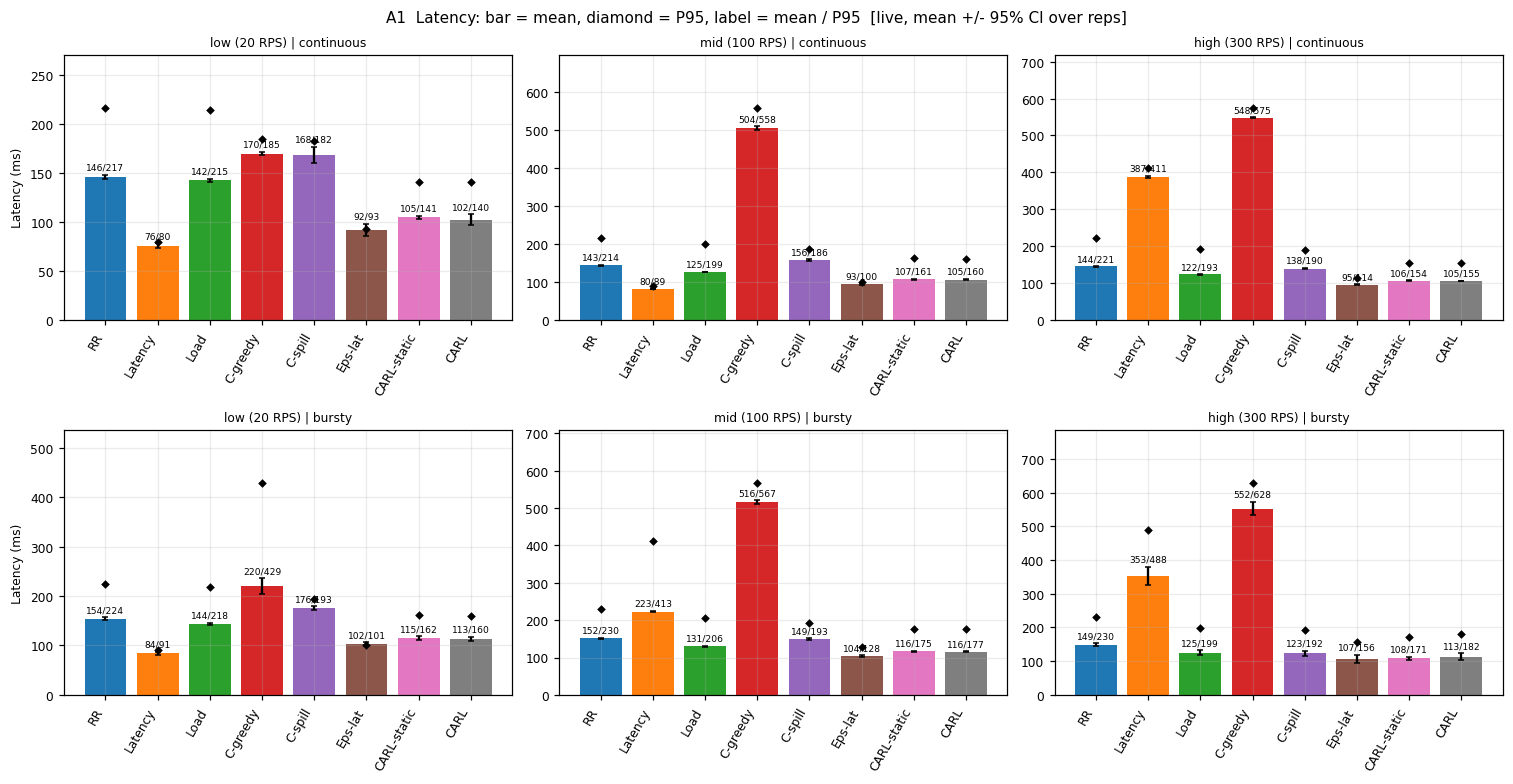

In [19]:
# CELL 18 — FIGURE A1: latency (model-based: RTT + queue + service + cold start; successful requests only)
facet_bars("lat_mean", "Latency (ms)", "A1  Latency: bar = mean, diamond = P95, label = mean / P95", "A1_latency",
           text_fn=lambda g: f"{g.lat_mean.mean():.0f}/{g.lat_p95.mean():.0f}", marker="lat_p95")

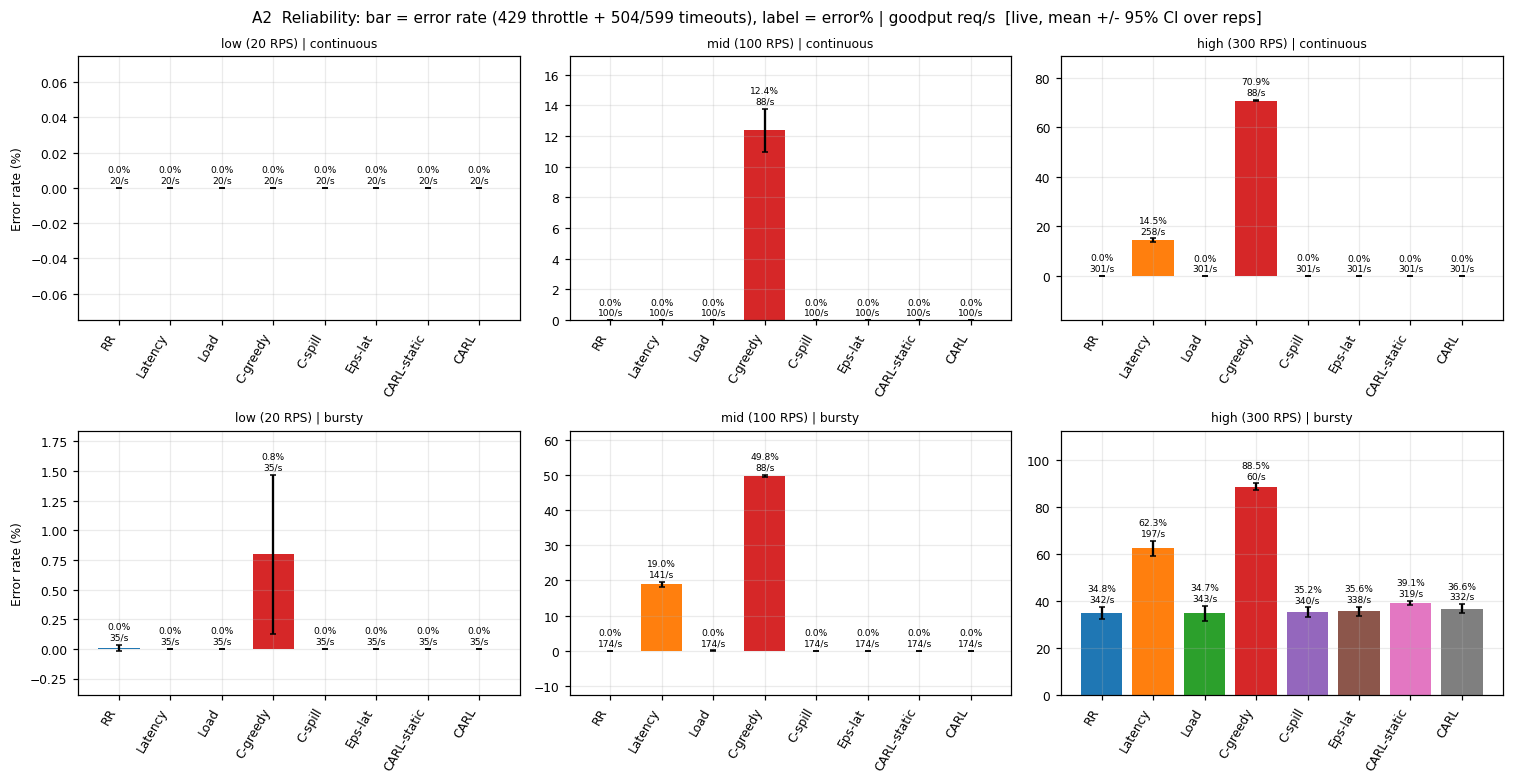

In [20]:
# CELL 19 — FIGURE A2: reliability (error rate) with goodput in the labels
facet_bars("error_pct", "Error rate (%)", "A2  Reliability: bar = error rate (429 throttle + 504/599 timeouts), label = error% | goodput req/s",
           "A2_reliability", text_fn=lambda g: f"{g.error_pct.mean():.1f}%\n{g.goodput_rps.mean():.0f}/s")

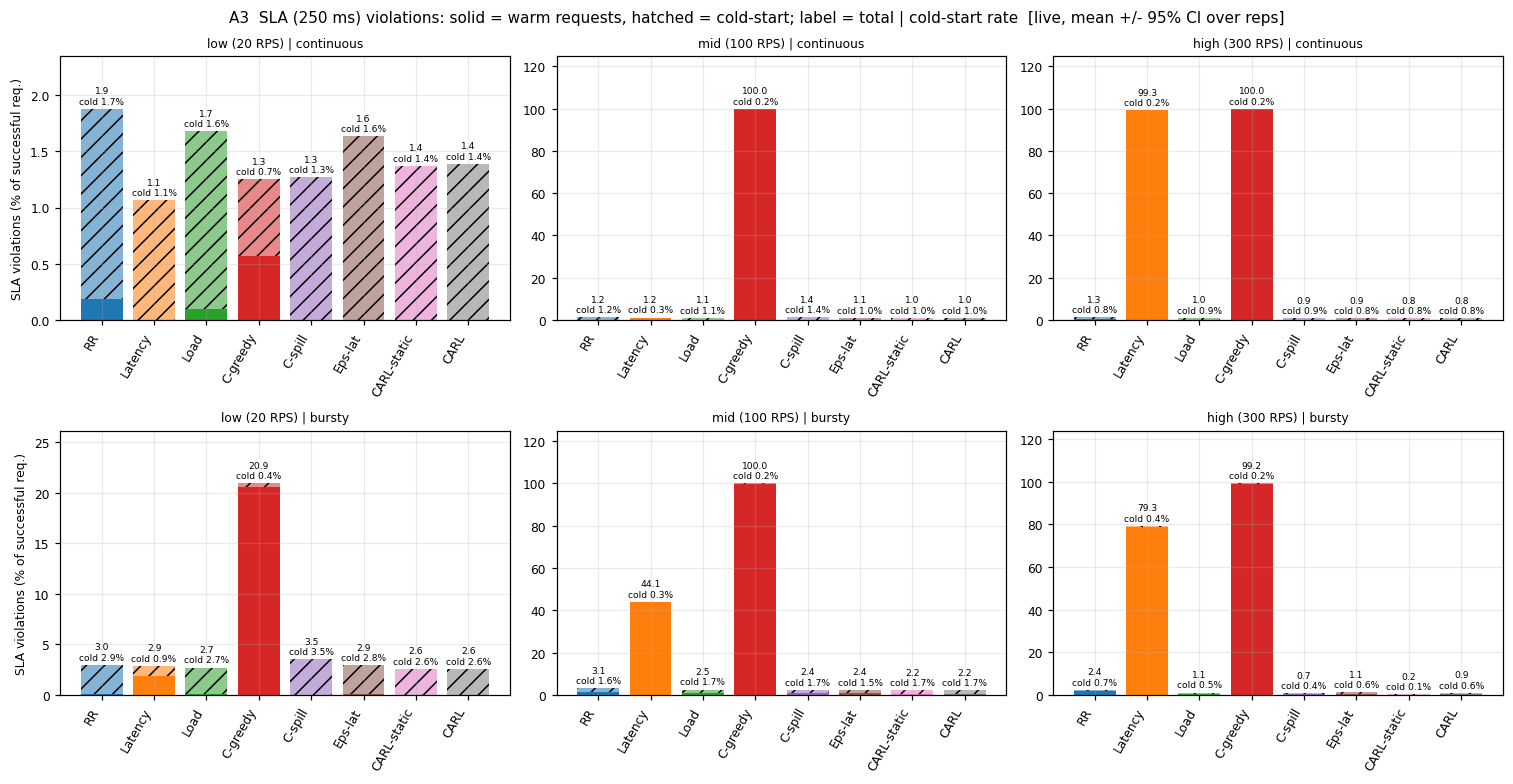

In [21]:
# CELL 20 — FIGURE A3: SLA violations split into warm-request vs cold-start-caused (R1-W3)
facet_bars(None, "SLA violations (% of successful req.)",
           f"A3  SLA ({CFG['sla_ms']:.0f} ms) violations: solid = warm requests, hatched = cold-start; label = total | cold-start rate",
           "A3_sla_decomposition", stack=("viol_warm_pct", "viol_cold_pct"),
           text_fn=lambda g: f"{g.viol_warm_pct.mean() + g.viol_cold_pct.mean():.1f}\ncold {g.cold_pct.mean():.1f}%")

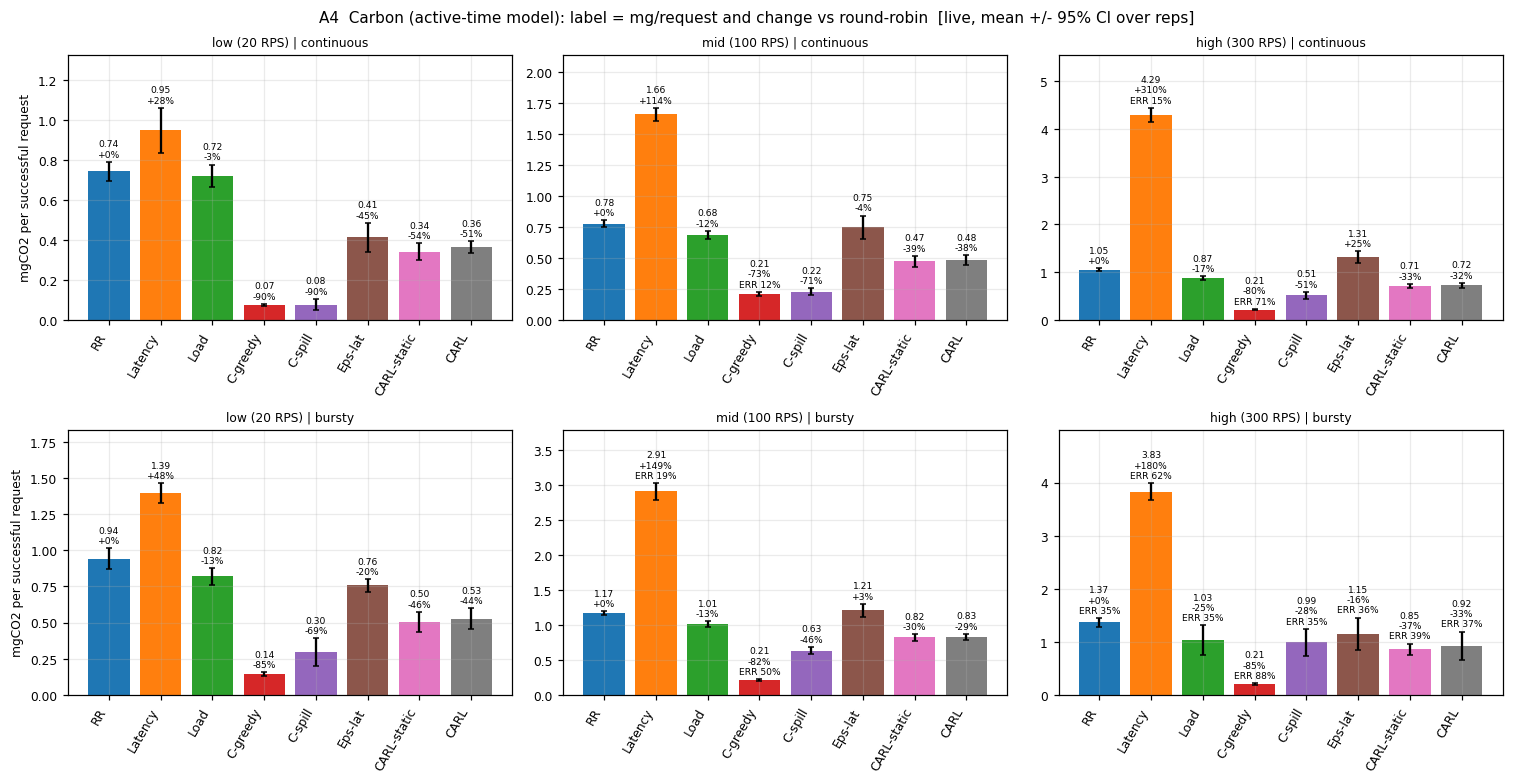

In [22]:
# CELL 21 — FIGURE A4: carbon per successful request (active-time energy model); label = value, % change vs round-robin, and ERR% when >=5% of requests fail
# (a policy that drops most requests looks 'green' per successful request -- always read it together with A2)
_d = main_data()
_rr = _d[_d["mode"] == "round_robin"].groupby(["level", "pattern"])["carbon_mg_per_req"].mean()
def _carbon_txt(g):
    lv, pt = g["level"].iloc[0], g["pattern"].iloc[0]; v = g.carbon_mg_per_req.mean()
    e = g.error_pct.mean()
    return f"{v:.2f}\n{100 * (v / _rr[(lv, pt)] - 1):+.0f}%" + (f"\nERR {e:.0f}%" if e >= 5 else "")
facet_bars("carbon_mg_per_req", "mgCO2 per successful request",
           "A4  Carbon (active-time model): label = mg/request and change vs round-robin", "A4_carbon", text_fn=_carbon_txt)

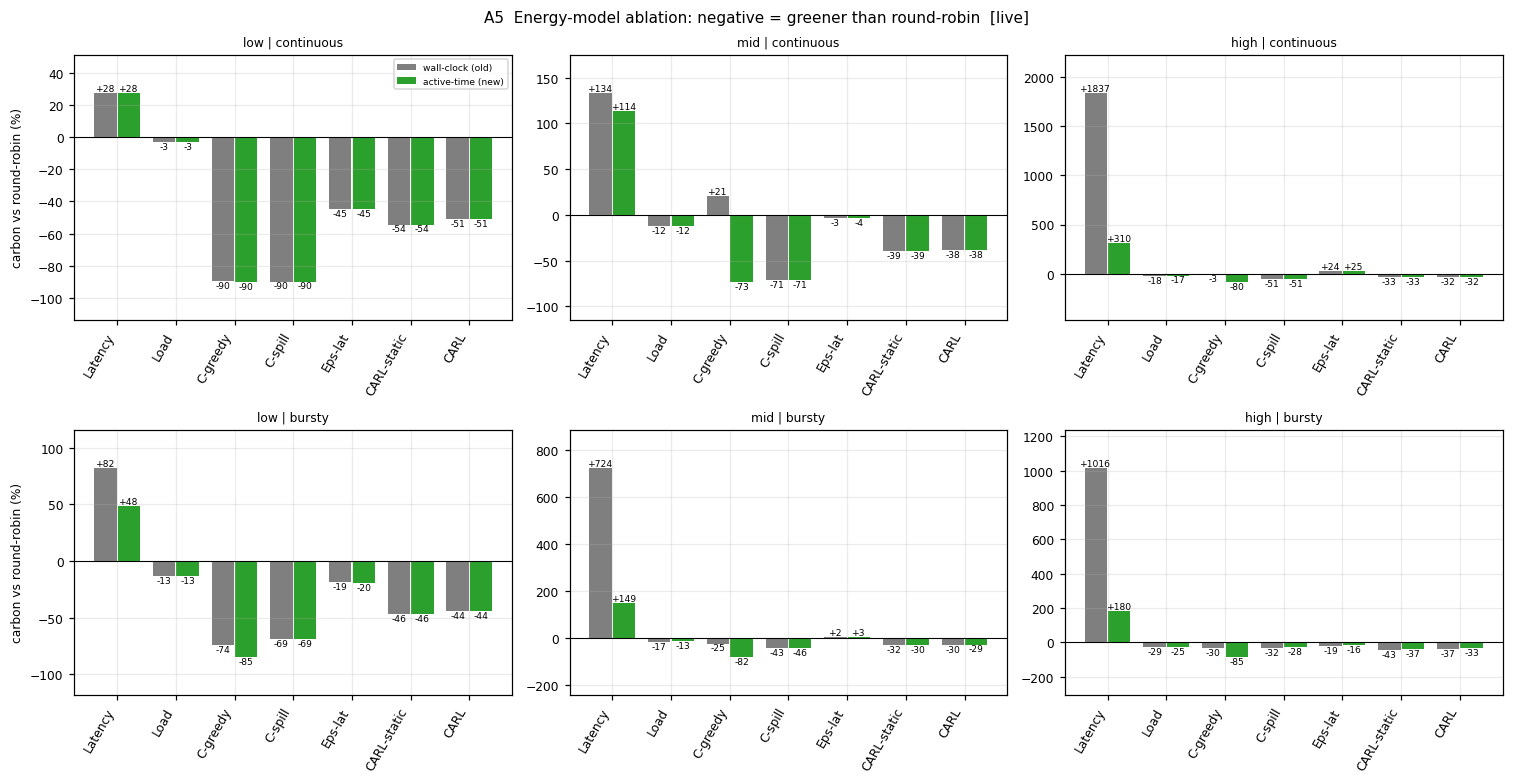

In [23]:
# CELL 22 — FIGURE A5: effect of the energy model (R1-W2 / R2-2): legacy wall-clock (queueing included) vs active-time
d = main_data(); modes = [m for m in modes_in(d) if m != "round_robin"]
fig, axs = plt.subplots(len(PATTERNS), len(LEVELS), figsize=(4.6 * len(LEVELS), 3.6 * len(PATTERNS)), squeeze=False)
for i, pat in enumerate(PATTERNS):
    for j, lv in enumerate(LEVELS):
        ax = axs[i][j]; g = d[(d.level == lv) & (d.pattern == pat)]
        rr = g[g["mode"] == "round_robin"]
        if not len(rr): continue
        for k, mo in enumerate(modes):
            gm = g[g["mode"] == mo]
            if not len(gm): continue
            for off, col, lab, c in [(-.2, "carbon_wall_mg_per_req", "wall-clock (old)", "tab:gray"), (.2, "carbon_mg_per_req", "active-time (new)", "tab:green")]:
                v = 100 * (gm[col].mean() / rr[col].mean() - 1)
                ax.bar(k + off, v, .38, color=c, label=lab if k == 0 else None)
                ax.annotate(f"{v:+.0f}", (k + off, v), ha="center", va="bottom" if v >= 0 else "top", fontsize=6)
        ax.axhline(0, color="k", lw=.7)
        ax.set_xticks(range(len(modes))); ax.set_xticklabels([MODE_NAME[m] for m in modes], rotation=60, ha="right")
        ax.set_title(f"{lv} | {pat}", fontsize=8); ax.margins(y=.2)
        if j == 0: ax.set_ylabel("carbon vs round-robin (%)")
        if i == 0 and j == 0: ax.legend(fontsize=6)
fig.suptitle(f"A5  Energy-model ablation: negative = greener than round-robin  [{SOURCE}]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A5_energy_model_ablation.png", dpi=200); plt.show()

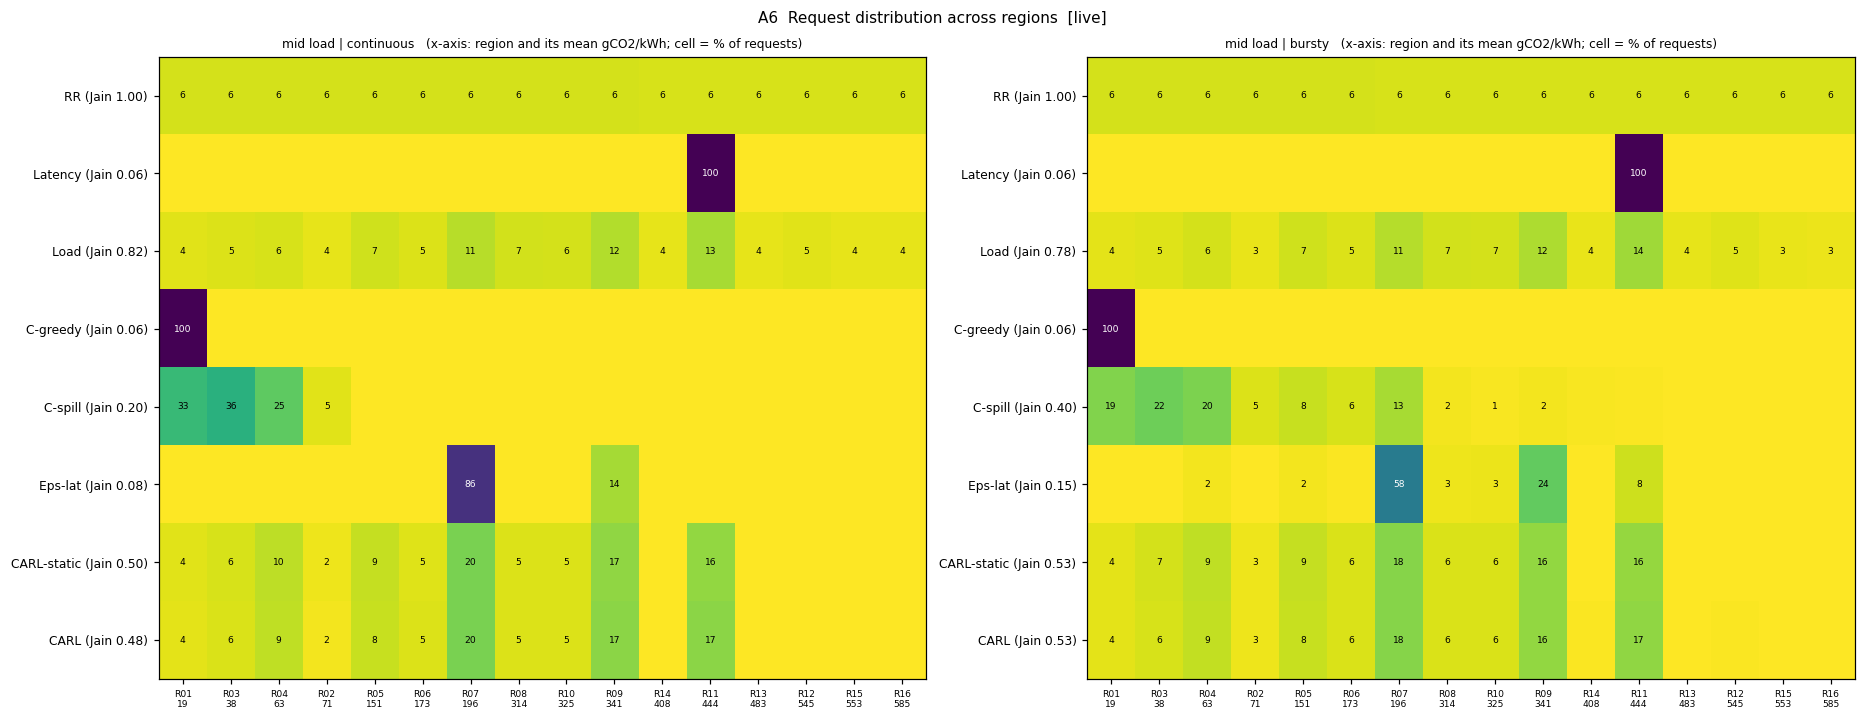

In [24]:
# CELL 23 — FIGURE A6: where does each policy send traffic? (share of requests per region, greenest -> dirtiest) + Jain index
LV = "mid" if "mid" in LEVELS else LEVELS[0]
order = sorted(TRACES, key=lambda r: np.mean(TRACES[r]))
d = main_data(); modes = modes_in(d)
fig, axs = plt.subplots(1, len(PATTERNS), figsize=(8.5 * len(PATTERNS), 0.55 * len(modes) + 2.2), squeeze=False)
for ax, pat in zip(axs[0], PATTERNS):
    g = d[(d.level == LV) & (d.pattern == pat)]
    mat = np.array([[np.mean([s.get(r, 0) for s in g[g["mode"] == mo]["share"]]) * 100 for r in order] for mo in modes])
    im = ax.imshow(mat, aspect="auto", cmap="viridis_r", vmin=0, vmax=max(30, mat.max()))
    for a in range(mat.shape[0]):
        for b in range(mat.shape[1]):
            if mat[a, b] >= 1: ax.text(b, a, f"{mat[a, b]:.0f}", ha="center", va="center", fontsize=6,
                                       color="w" if mat[a, b] > .55 * mat.max() else "k")
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{r}\n{np.mean(TRACES[r]):.0f}" for r in order], fontsize=6)
    ax.set_yticks(range(len(modes)))
    ax.set_yticklabels([f"{MODE_NAME[m]} (Jain {g[g['mode'] == m]['jain'].mean():.2f})" for m in modes])
    ax.set_title(f"{LV} load | {pat}   (x-axis: region and its mean gCO2/kWh; cell = % of requests)", fontsize=8); ax.grid(False)
fig.suptitle(f"A6  Request distribution across regions  [{SOURCE}]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A6_region_distribution.png", dpi=200); plt.show()

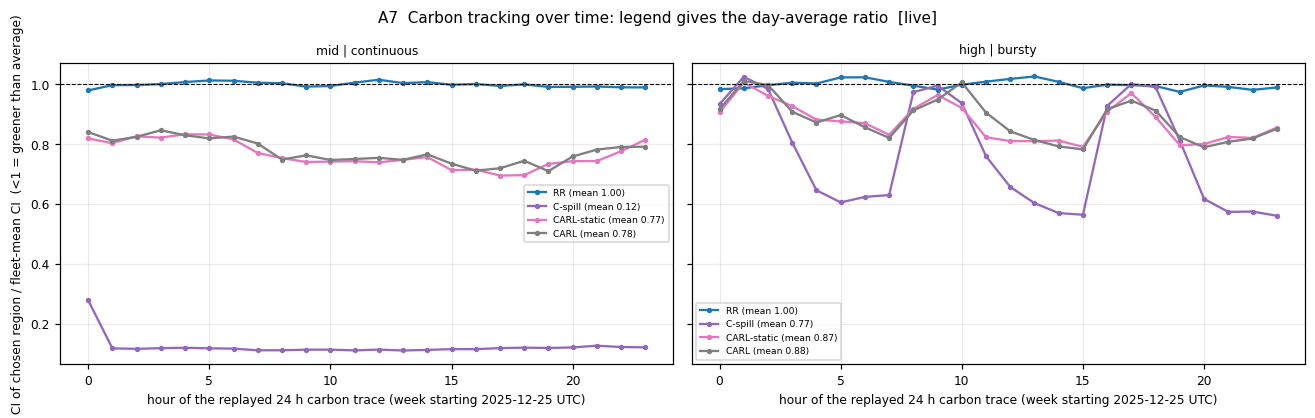

In [25]:
# CELL 24 — FIGURE A7: does live carbon information help? chosen-region CI relative to fleet-mean CI over the replayed day (R1-W4)
d = main_data()
fleet = lambda rep: np.array([np.mean([TRACES[r][(24 * (rep % TRACE_DAYS) + h) % len(TRACES[r])] for r in TRACES]) for h in range(24)])
sel = [m for m in ["round_robin", "carbon_spill", "carl_static", "carl"] if m in set(d["mode"])]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (lv, pat) in zip(axs, [(LV, "continuous"), (LEVELS[-1], "bursty")]):
    for mo in sel:
        g = d[(d.level == lv) & (d.pattern == pat) & (d["mode"] == mo)]
        if not len(g): continue
        R = np.array([np.array(r.ci_hour) / fleet(r.rep) for r in g.itertuples()])
        mu = np.nanmean(R, axis=0)
        ax.plot(range(24), mu, marker="o", ms=2.5, color=MODE_COLOR[mo], label=f"{MODE_NAME[mo]} (mean {np.nanmean(mu):.2f})")
    ax.axhline(1, color="k", lw=.7, ls="--"); ax.set_xlabel(f"hour of the replayed 24 h carbon trace (week starting {TRACE_META['week_start']} UTC)")
    ax.set_title(f"{lv} | {pat}", fontsize=8); ax.legend(fontsize=6)
axs[0].set_ylabel("CI of chosen region / fleet-mean CI  (<1 = greener than average)")
fig.suptitle(f"A7  Carbon tracking over time: legend gives the day-average ratio  [{SOURCE}]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A7_carbon_tracking.png", dpi=200); plt.show()

In [26]:
# CELL 25 — TABLE A8: inferential statistics ONLY (Welch t-test, Holm-corrected p, Cohen's d). Descriptive values live in the figures.
d = main_data(); METS = dict(lat_mean="Latency", carbon_mg_per_req="Carbon/req", error_pct="Error rate")
rows = []
for (lv, pat), g in d.groupby(["level", "pattern"]):
    c = g[g["mode"] == "carl"]
    for bm in [m for m in modes_in(d) if m != "carl"]:
        b = g[g["mode"] == bm]
        if len(c) < 2 or len(b) < 2: continue
        r = dict(level=lv, pattern=pat, baseline=MODE_NAME[bm])
        for k in METS:
            x, y = c[k].dropna().to_numpy(), b[k].dropna().to_numpy()
            if len(x) < 2 or len(y) < 2: r[k + "_p"] = np.nan; r[k + "_d"] = np.nan; continue
            r[k + "_p"] = sps.ttest_ind(x, y, equal_var=False).pvalue
            sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
            r[k + "_d"] = (x.mean() - y.mean()) / sp if sp > 1e-12 else 0.0
        rows.append(r)
T = pd.DataFrame(rows)
assert len(T), "need >= 2 repetitions per configuration for the t-tests"
for k in METS:                                           # Holm step-down within each metric family
    p = T[k + "_p"].to_numpy(float); idx = np.argsort(np.where(np.isnan(p), 2, p)); adj = np.full(len(p), np.nan); run_max = 0.0
    n_valid = int((~np.isnan(p)).sum())
    for rank, i in enumerate(idx[:n_valid]):
        run_max = max(run_max, min(1.0, (n_valid - rank) * p[i])); adj[i] = run_max
    T[k + "_p"] = adj
fmt_p = lambda v: "n/a" if np.isnan(v) else ("<0.001" if v < 1e-3 else f"{v:.3f}")
out = T[["level", "pattern", "baseline"]].copy()
for k, nm in METS.items():
    out[f"{nm}: d"] = T[k + "_d"].round(2); out[f"{nm}: p(Holm)"] = T[k + "_p"].map(fmt_p)
out.to_csv("analysis/A8_significance_tests.csv", index=False)
print("A8: CARL vs each baseline. Cohen's d < 0 means CARL has the LOWER value (better for all three metrics). n/a = zero variance in both groups.")
display(out.set_index(["level", "pattern", "baseline"]))

A8: CARL vs each baseline. Cohen's d < 0 means CARL has the LOWER value (better for all three metrics). n/a = zero variance in both groups.


Latency: d Latency: p(Holm)  Carbon/req: d  \
level pattern    baseline                                                  
high  bursty     RR                -5.73            0.004          -2.76   
                 Latency          -14.76           <0.001         -16.18   
                 Load              -1.68            0.291          -0.48   
                 C-greedy         -34.43           <0.001           4.61   
                 C-spill           -1.39            0.495          -0.31   
                 Eps-lat            0.68            1.000          -0.99   
                 CARL-static        0.75            1.000           0.40   
      continuous RR               -87.29           <0.001          -9.25   
                 Latency         -133.98           <0.001         -39.01   
                 Load             -28.16           <0.001          -3.73   
                 C-greedy        -931.10           <0.001          15.86   
                 C-spill          -23.38           <0.001           4.05   
                 Eps-lat           23.94           <0.001          -7.75   
                 CARL-static       -1.17            0.717           0.24   
low   bursty     RR               -14.74           <0.001          -7.09   
                 Latency           10.13           <0.001         -15.26   
                 Load             -12.47           <0.001          -5.62   
                 C-greedy         -11.84           <0.001           9.21   
                 C-spill          -19.79           <0.001           3.43   
                 Eps-lat            3.45            0.007          -4.85   
                 CARL-static       -0.58            1.000           0.40   
      continuous RR               -12.60           <0.001         -12.00   
                 Latency            7.44           <0.001          -8.86   
                 Load             -11.84           <0.001          -9.89   
                 C-greedy         -19.92           <0.001          16.32   
                 C-spill          -11.65           <0.001          12.16   
                 Eps-lat            2.14            0.097          -1.11   
                 CARL-static       -0.78            1.000           0.78   
mid   bursty     RR               -39.06           <0.001         -11.86   
                 Latency          -99.60           <0.001         -28.56   
                 Load             -21.96           <0.001          -5.24   
                 C-greedy        -148.47           <0.001          23.77   
                 C-spill          -24.48           <0.001           5.03   
                 Eps-lat           10.22           <0.001          -6.52   
                 CARL-static       -0.27            1.000           0.32   
      continuous RR               -37.43           <0.001         -10.88   
                 Latency           23.66           <0.001         -31.35   
                 Load             -19.74           <0.001          -6.80   
                 C-greedy        -142.13           <0.001          10.81   
                 C-spill          -28.11           <0.001           9.10   
                 Eps-lat            7.15           <0.001          -4.61   
                 CARL-static       -1.12            0.717           0.19   

                             Carbon/req: p(Holm)  Error rate: d  \
level pattern    baseline                                         
high  bursty     RR                        0.092           1.00   
                 Latency                  <0.001         -11.78   
                 Load                      1.000           0.91   
                 C-greedy                  0.022         -37.50   
                 C-spill                   1.000           0.91   
                 Eps-lat                   1.000           0.66   
                 CARL-static               1.000          -1.97   
      continuous RR                       <0.001          -1.55   
               

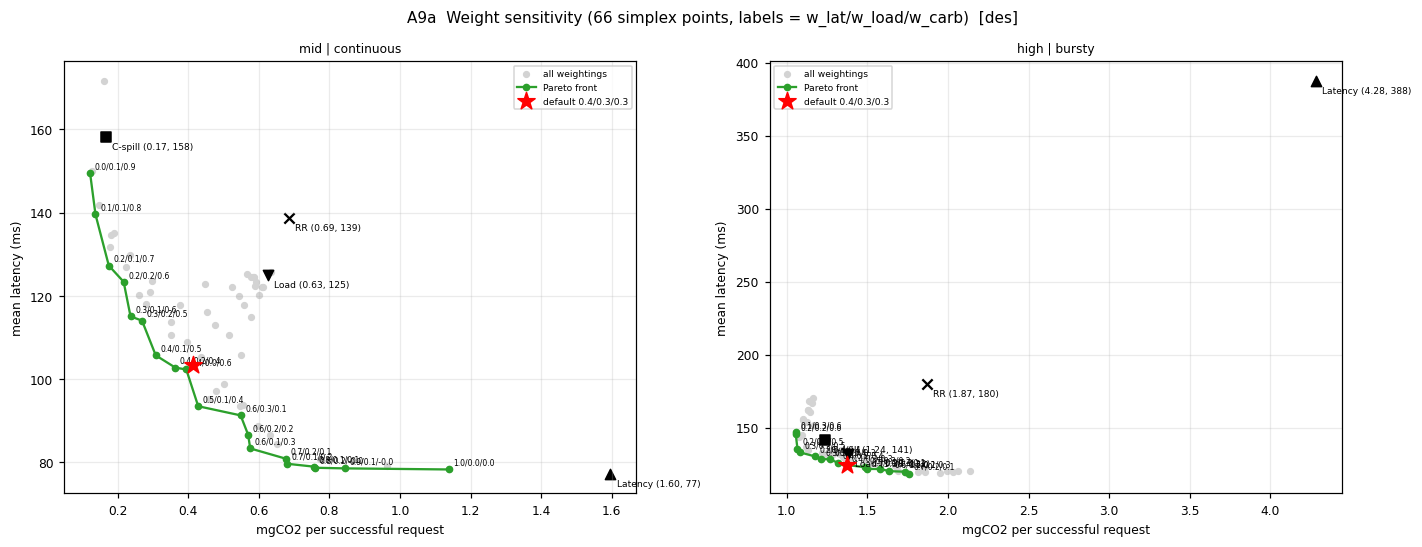

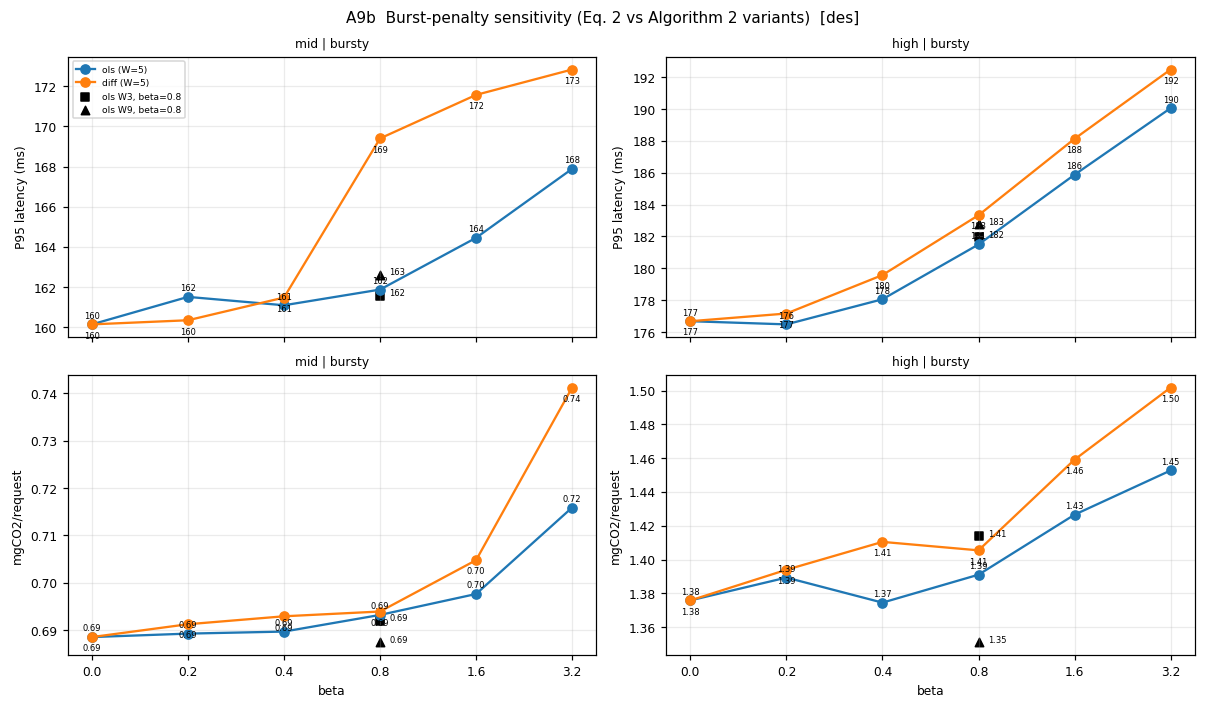

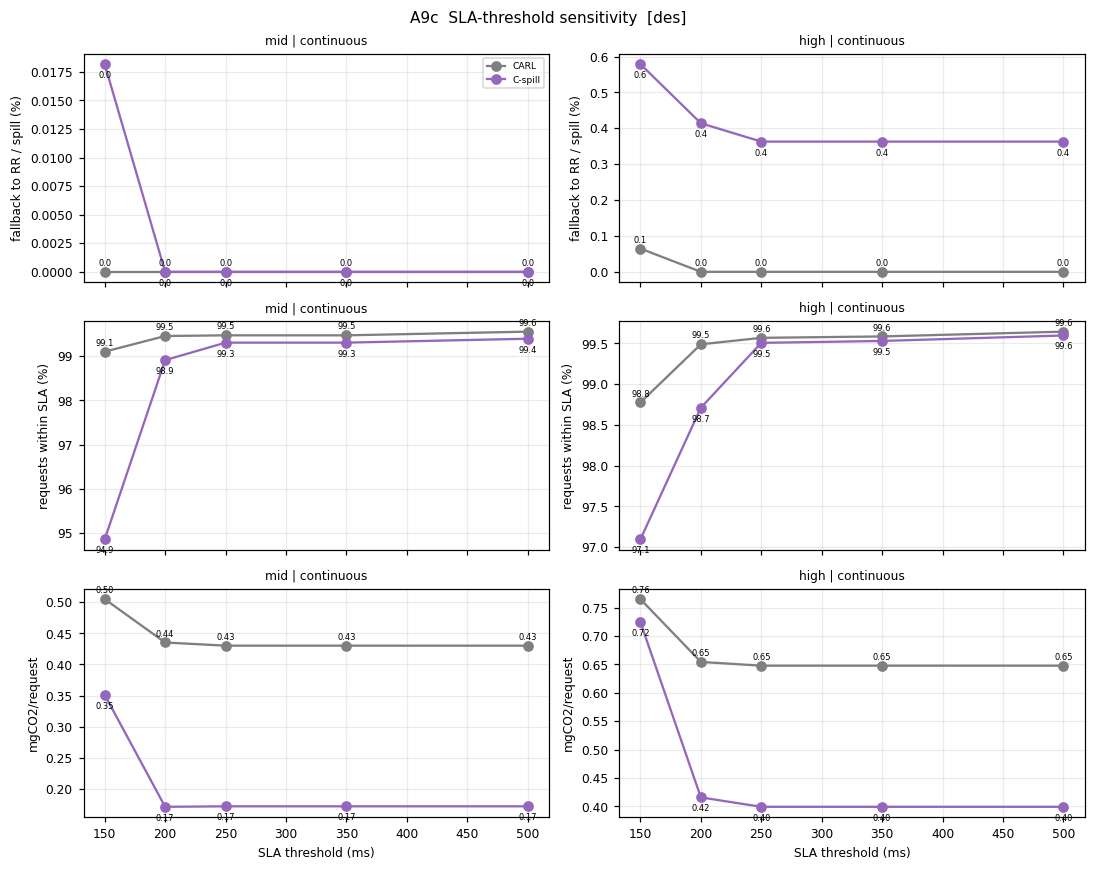

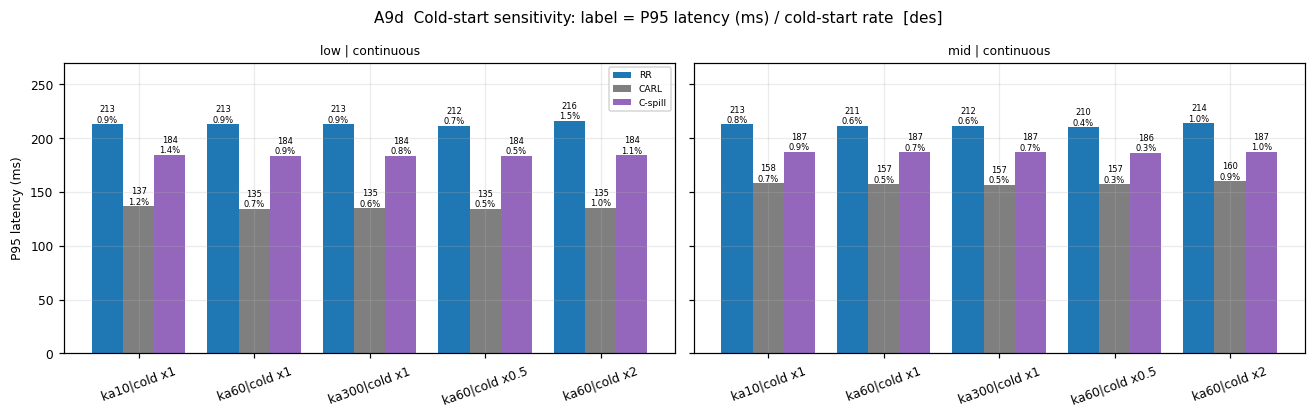

In [27]:
# CELL 26 — FIGURES A9a-d: sensitivity analyses (simulator)
def pareto_mask(P):
    keep = np.ones(len(P), bool)
    for i in range(len(P)):
        keep[i] = not any((P[j] <= P[i]).all() and (P[j] < P[i]).any() for j in range(len(P)) if j != i)
    return keep

# ---- A9a: weight simplex -> carbon/latency Pareto frontier (label = w_lat/w_load/w_carb) ----
W = des_sens["sens_w"]; sc = [("mid", "continuous"), ("high", "bursty")]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (lv, pat) in zip(axs, sc):
    g = W[(W.level == lv) & (W.pattern == pat)].groupby("label")[["carbon_mg_per_req", "lat_mean", "error_pct"]].mean().dropna()
    g = g[g.error_pct < 5]                                    # exclude configurations that fail
    P = g[["carbon_mg_per_req", "lat_mean"]].to_numpy(); pm = pareto_mask(P)
    ax.scatter(P[:, 0], P[:, 1], c="lightgray", s=14, label="all weightings")
    front = g[pm].sort_values("carbon_mg_per_req")
    ax.plot(front.carbon_mg_per_req, front.lat_mean, "-o", color="tab:green", ms=4, label="Pareto front")
    for lab, r in front.iterrows():
        ax.annotate(lab, (r.carbon_mg_per_req, r.lat_mean), fontsize=5, xytext=(3, 3), textcoords="offset points")
    if "0.4/0.3/0.3" in g.index:
        r = g.loc["0.4/0.3/0.3"]; ax.scatter(r.carbon_mg_per_req, r.lat_mean, marker="*", s=140, c="red", label="default 0.4/0.3/0.3", zorder=5)
    b = main_data("des"); b = b[(b.level == lv) & (b.pattern == pat)]
    for mo, mk in [("round_robin", "x"), ("carbon_spill", "s"), ("latency", "^"), ("load", "v")]:
        gm = b[b["mode"] == mo]
        if len(gm):
            ax.scatter(gm.carbon_mg_per_req.mean(), gm.lat_mean.mean(), marker=mk, s=45, c="k")
            ax.annotate(f"{MODE_NAME[mo]} ({gm.carbon_mg_per_req.mean():.2f}, {gm.lat_mean.mean():.0f})",
                        (gm.carbon_mg_per_req.mean(), gm.lat_mean.mean()), fontsize=6, xytext=(4, -8), textcoords="offset points")
    ax.set_xlabel("mgCO2 per successful request"); ax.set_ylabel("mean latency (ms)"); ax.set_title(f"{lv} | {pat}", fontsize=8); ax.legend(fontsize=6)
fig.suptitle("A9a  Weight sensitivity (66 simplex points, labels = w_lat/w_load/w_carb)  [des]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A9a_weight_pareto.png", dpi=200); plt.show()

# ---- A9b: burst coefficient beta, estimator (regression slope vs difference), window length ----
B = des_sens["sens_beta"].copy(); B["est"] = B.label.str.split("|").str[0]; B["win"] = B.label.str.split("|").str[1]
B["beta_v"] = B.label.str.split("|").str[2].str[1:].astype(float)
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for j, lv in enumerate(["mid", "high"]):
    for i, (met, yl) in enumerate([("lat_p95", "P95 latency (ms)"), ("carbon_mg_per_req", "mgCO2/request")]):
        ax = axs[i][j]
        for est, col in [("ols", "tab:blue"), ("diff", "tab:orange")]:
            g = B[(B.level == lv) & (B.est == est) & (B.win == "W5")].groupby("beta_v")[met].mean()
            ax.plot(range(len(g)), g.values, "-o", color=col, label=f"{est} (W=5)")
            for k, v in enumerate(g.values): ax.annotate(f"{v:.2f}" if met != "lat_p95" else f"{v:.0f}", (k, v), fontsize=5.5, xytext=(0, 4 if est == "ols" else -9), textcoords="offset points", ha="center")
        for w, mk in [("W3", "s"), ("W9", "^")]:
            g = B[(B.level == lv) & (B.win == w)][met].mean(); k0 = list(sorted(B.beta_v.unique())).index(0.8)
            ax.scatter(k0, g, marker=mk, c="k", s=30, label=f"ols {w}, beta=0.8"); ax.annotate(f"{g:.2f}" if met != "lat_p95" else f"{g:.0f}", (k0, g), fontsize=5.5, xytext=(6, 0), textcoords="offset points")
        ax.set_xticks(range(len(sorted(B.beta_v.unique())))); ax.set_xticklabels(sorted(B.beta_v.unique()))
        ax.set_ylabel(yl); ax.set_title(f"{lv} | bursty", fontsize=8)
        if i == 1: ax.set_xlabel("beta")
        if i == 0 and j == 0: ax.legend(fontsize=6)
fig.suptitle("A9b  Burst-penalty sensitivity (Eq. 2 vs Algorithm 2 variants)  [des]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A9b_burst_sensitivity.png", dpi=200); plt.show()

# ---- A9c: SLA threshold -> fallback frequency, SLA attainment, carbon ----
S = des_sens["sens_sla"].copy(); S["sla"] = S.label.astype(float)
fig, axs = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for j, lv in enumerate(["mid", "high"]):
    for i, (met, yl) in enumerate([("fallback_pct", "fallback to RR / spill (%)"), ("sla_attain_all_pct", "requests within SLA (%)"),
                                   ("carbon_mg_per_req", "mgCO2/request")]):
        ax = axs[i][j]
        for mo in ["carl", "carbon_spill"]:
            g = S[(S.level == lv) & (S["mode"] == mo)].groupby("sla")[met].mean()
            ax.plot(g.index, g.values, "-o", color=MODE_COLOR[mo], label=MODE_NAME[mo])
            for x, v in g.items(): ax.annotate(f"{v:.1f}" if met != "carbon_mg_per_req" else f"{v:.2f}", (x, v), fontsize=5.5, xytext=(0, 4 if mo == "carl" else -9), textcoords="offset points", ha="center")
        ax.set_ylabel(yl); ax.set_title(f"{lv} | continuous", fontsize=8)
        if i == 2: ax.set_xlabel("SLA threshold (ms)")
        if i == 0 and j == 0: ax.legend(fontsize=6)
fig.suptitle("A9c  SLA-threshold sensitivity  [des]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A9c_sla_sensitivity.png", dpi=200); plt.show()

# ---- A9d: cold-start model (keep-alive window, cold-start magnitude) ----
C = des_sens["sens_cold"]; cfgs = ["ka10|cold x1", "ka60|cold x1", "ka300|cold x1", "ka60|cold x0.5", "ka60|cold x2"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, lv in zip(axs, ["low", "mid"]):
    for k, mo in enumerate(["round_robin", "carl", "carbon_spill"]):
        g = C[(C.level == lv) & (C["mode"] == mo)].groupby("label")[["lat_p95", "cold_pct"]].mean().reindex(cfgs)
        ax.bar(np.arange(len(cfgs)) + (k - 1) * .27, g.lat_p95, .27, color=MODE_COLOR[mo], label=MODE_NAME[mo])
        for x, (v, c) in enumerate(zip(g.lat_p95, g.cold_pct)): ax.annotate(f"{v:.0f}\n{c:.1f}%", (x + (k - 1) * .27, v), ha="center", va="bottom", fontsize=5.5)
    ax.set_xticks(range(len(cfgs))); ax.set_xticklabels(cfgs, rotation=20); ax.set_title(f"{lv} | continuous", fontsize=8); ax.margins(y=.25)
axs[0].set_ylabel("P95 latency (ms)"); axs[0].legend(fontsize=6)
fig.suptitle("A9d  Cold-start sensitivity: label = P95 latency (ms) / cold-start rate  [des]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A9d_cold_start_sensitivity.png", dpi=200); plt.show()

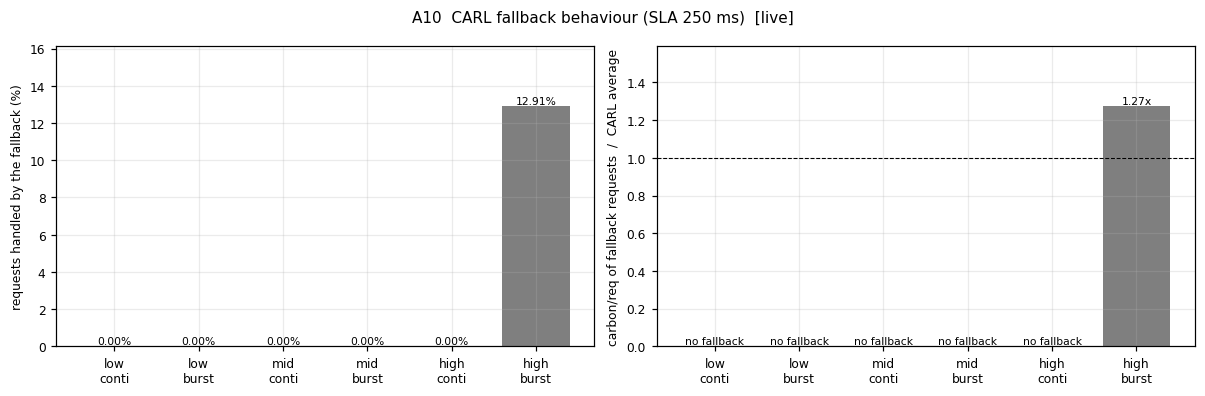

In [28]:
# CELL 27 — FIGURE A10: round-robin fallback inside CARL (R2-5): how often it fires and what it costs in carbon
d = main_data(); g = d[d["mode"] == "carl"]
keys = [(l, p) for l in LEVELS for p in PATTERNS]; lab = [f"{l}\n{p[:5]}" for l, p in keys]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
fb = [g[(g.level == l) & (g.pattern == p)].fallback_pct.mean() for l, p in keys]
axs[0].bar(range(len(keys)), fb, color=MODE_COLOR["carl"])
for x, v in enumerate(fb): axs[0].annotate(f"{v:.2f}%", (x, v), ha="center", va="bottom", fontsize=7)
axs[0].set_xticks(range(len(keys))); axs[0].set_xticklabels(lab); axs[0].set_ylabel("requests handled by the fallback (%)"); axs[0].margins(y=.25)
ratio = []
for l, p in keys:
    x = g[(g.level == l) & (g.pattern == p)]
    ratio.append((x.carbon_fb_mg_per_req / x.carbon_mg_per_req).mean())
axs[1].bar(range(len(keys)), [0 if np.isnan(r) else r for r in ratio], color="tab:gray")
for x, v in enumerate(ratio): axs[1].annotate("no fallback" if np.isnan(v) else f"{v:.2f}x", (x, 0 if np.isnan(v) else v), ha="center", va="bottom", fontsize=7)
axs[1].axhline(1, color="k", lw=.7, ls="--"); axs[1].set_xticks(range(len(keys))); axs[1].set_xticklabels(lab)
axs[1].set_ylabel("carbon/req of fallback requests  /  CARL average"); axs[1].margins(y=.25)
fig.suptitle(f"A10  CARL fallback behaviour (SLA {CFG['sla_ms']:.0f} ms)  [{SOURCE}]", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A10_fallback.png", dpi=200); plt.show()

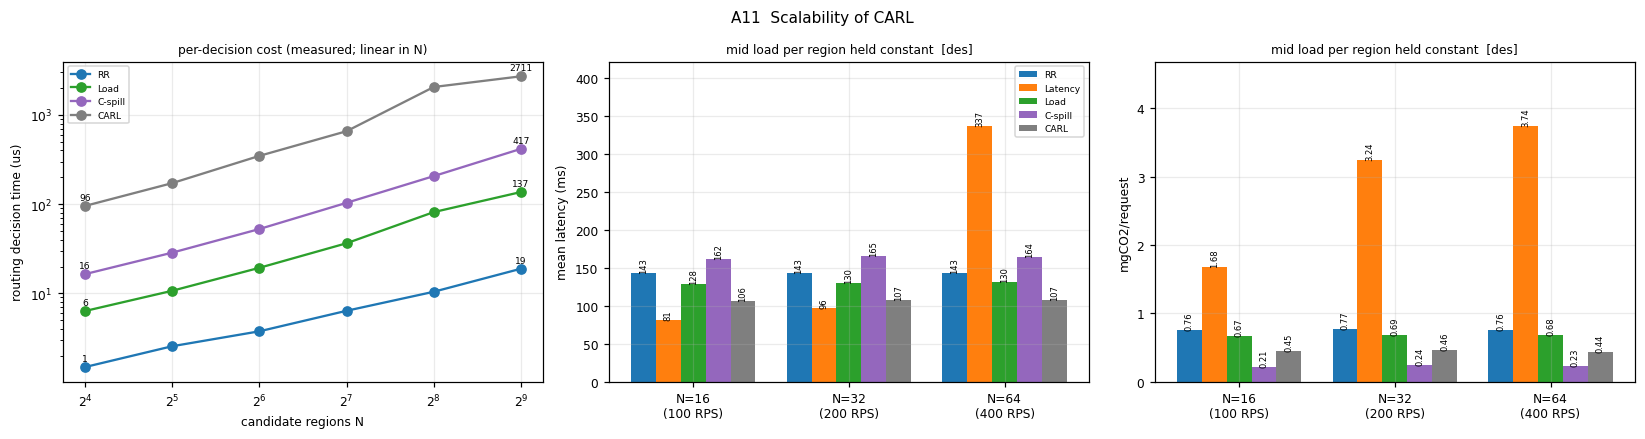

In [29]:
# CELL 28 — FIGURE A11: scalability beyond 16 regions (R2-5)
dt = pd.read_csv("analysis/decision_time.csv"); sc = des_scale
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for mo in dt["mode"].unique():
    g = dt[dt["mode"] == mo]; axs[0].plot(g.n_regions, g.decision_us, "-o", color=MODE_COLOR[mo], label=MODE_NAME[mo])
    for _, r in g[g.n_regions.isin([16, 512])].iterrows(): axs[0].annotate(f"{r.decision_us:.0f}", (r.n_regions, r.decision_us), fontsize=6, xytext=(0, 4), textcoords="offset points", ha="center")
axs[0].set_xscale("log", base=2); axs[0].set_yscale("log"); axs[0].set_xlabel("candidate regions N"); axs[0].set_ylabel("routing decision time (us)")
axs[0].set_title("per-decision cost (measured; linear in N)", fontsize=8); axs[0].legend(fontsize=6)
ns = sorted(sc.n_regions.unique()); smodes = [m for m in MODE_ORDER if m in set(sc["mode"])]
for ax, (met, yl, f) in zip(axs[1:], [("lat_mean", "mean latency (ms)", "{:.0f}"), ("carbon_mg_per_req", "mgCO2/request", "{:.2f}")]):
    for k, mo in enumerate(smodes):
        v = [sc[(sc.n_regions == n) & (sc["mode"] == mo)][met].mean() for n in ns]
        xs = np.arange(len(ns)) + (k - len(smodes) / 2 + .5) * .16
        ax.bar(xs, v, .16, color=MODE_COLOR[mo], label=MODE_NAME[mo])
        for x, y in zip(xs, v): ax.annotate(f.format(y), (x, y), ha="center", va="bottom", fontsize=5.5, rotation=90)
    ax.set_xticks(range(len(ns))); ax.set_xticklabels([f"N={n}\n({int(LEVELS_RPS['mid'] * n / 16)} RPS)" for n in ns]); ax.set_ylabel(yl); ax.margins(y=.25)
    ax.set_title("mid load per region held constant  [des]", fontsize=8)
axs[1].legend(fontsize=6)
fig.suptitle("A11  Scalability of CARL", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A11_scalability.png", dpi=200); plt.show()

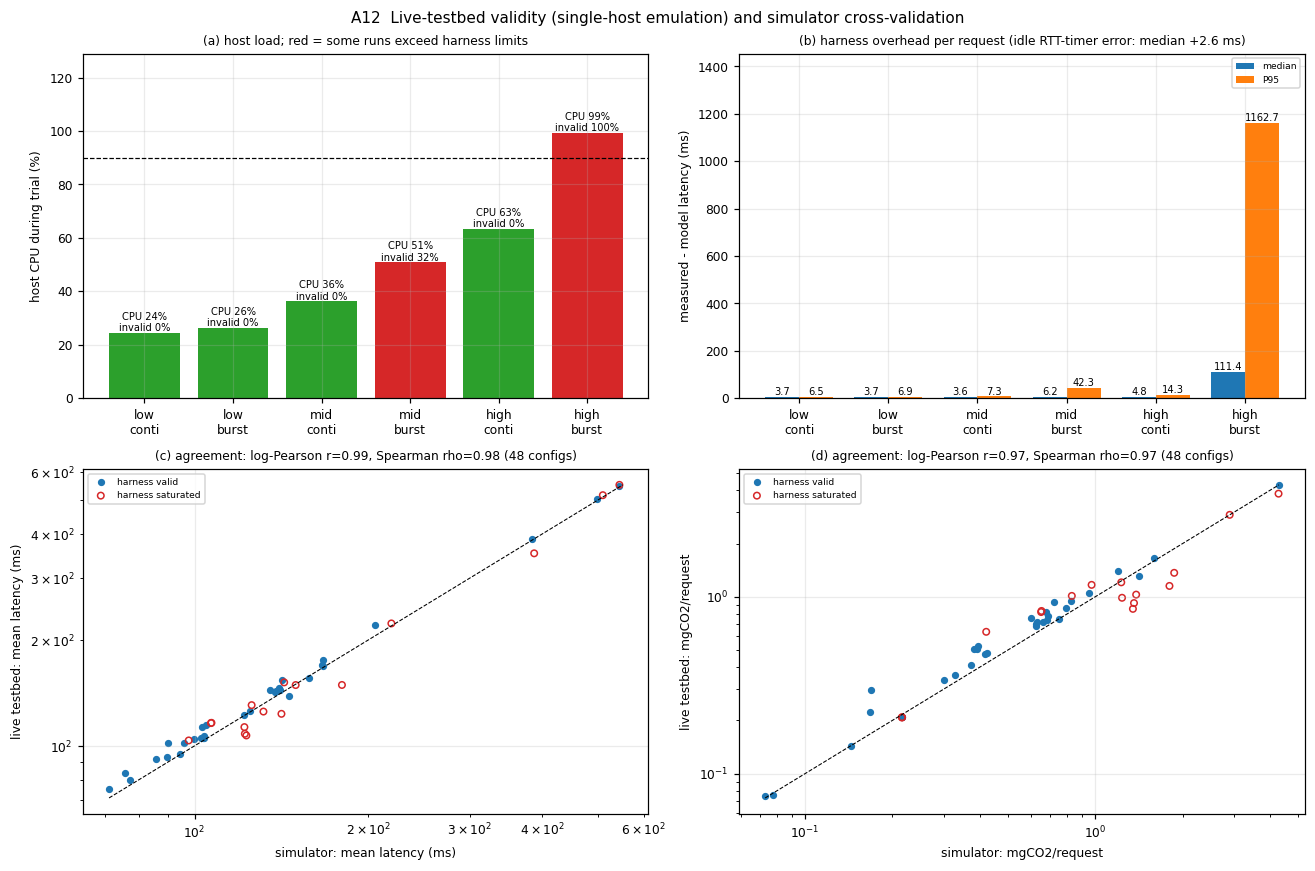

In [30]:
# CELL 29 — FIGURE A12: is the live testbed trustworthy? (R1-W1)  harness load, harness overhead, and agreement with the simulator
lv_ = live.copy()
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
keys = [(l, p) for l in LEVELS for p in PATTERNS]; lab = [f"{l}\n{p[:5]}" for l, p in keys]
# (a) CPU load of the host + share of invalid runs
cpu = [lv_[(lv_.level == l) & (lv_.pattern == p)].cpu_mean.mean() for l, p in keys]
inv = [100 * (~lv_[(lv_.level == l) & (lv_.pattern == p)].harness_ok).mean() for l, p in keys]
axs[0][0].bar(range(len(keys)), cpu, color=["tab:red" if i > 0 else "tab:green" for i in inv])
for x, (c, i) in enumerate(zip(cpu, inv)): axs[0][0].annotate(f"CPU {c:.0f}%\ninvalid {i:.0f}%", (x, c), ha="center", va="bottom", fontsize=6.5)
axs[0][0].axhline(HARNESS_LIMITS["cpu_mean"], color="k", ls="--", lw=.8); axs[0][0].set_xticks(range(len(keys))); axs[0][0].set_xticklabels(lab)
axs[0][0].set_ylabel("host CPU during trial (%)"); axs[0][0].set_title("(a) host load; red = some runs exceed harness limits", fontsize=8); axs[0][0].margins(y=.3)
# (b) harness overhead = client-measured latency - model latency
w = .38; x = np.arange(len(keys))
p50 = [lv_[(lv_.level == l) & (lv_.pattern == p)].ovh_p50.mean() for l, p in keys]; p95 = [lv_[(lv_.level == l) & (lv_.pattern == p)].ovh_p95.mean() for l, p in keys]
axs[0][1].bar(x - w / 2, p50, w, label="median"); axs[0][1].bar(x + w / 2, p95, w, label="P95")
for xi, a, b in zip(x, p50, p95):
    axs[0][1].annotate(f"{a:.1f}", (xi - w / 2, a), ha="center", va="bottom", fontsize=6.5); axs[0][1].annotate(f"{b:.1f}", (xi + w / 2, b), ha="center", va="bottom", fontsize=6.5)
fid = pd.read_csv("analysis/rtt_timer_fidelity.csv"); err = (fid.measured_median_ms - fid.nominal_ms).median()
axs[0][1].set_xticks(x); axs[0][1].set_xticklabels(lab); axs[0][1].set_ylabel("measured - model latency (ms)"); axs[0][1].legend(fontsize=6); axs[0][1].margins(y=.25)
axs[0][1].set_title(f"(b) harness overhead per request (idle RTT-timer error: median {err:+.1f} ms)", fontsize=8)
# (c,d) live vs simulator agreement on identical configurations
A = M[(M.tag == "main")].groupby(["source", "level", "pattern", "mode"])[["lat_mean", "carbon_mg_per_req"]].mean().unstack(0).dropna()
okmask = lv_.groupby(["level", "pattern"]).harness_ok.all()
for ax, met, nm in [(axs[1][0], "lat_mean", "mean latency (ms)"), (axs[1][1], "carbon_mg_per_req", "mgCO2/request")]:
    if ("live" not in A[met]) or ("des" not in A[met]) or len(A) < 3:
        ax.text(.5, .5, "need both live and des runs", ha="center"); continue
    xs, ys = A[met]["des"].to_numpy(), A[met]["live"].to_numpy()
    valid = np.array([okmask.get((l, p), False) for l, p, _ in A.index])
    ax.scatter(xs[valid], ys[valid], s=14, c="tab:blue", label="harness valid"); ax.scatter(xs[~valid], ys[~valid], s=18, facecolors="none", edgecolors="tab:red", label="harness saturated")
    lim = [min(xs.min(), ys.min()), max(xs.max(), ys.max())]; ax.plot(lim, lim, "k--", lw=.7)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(f"simulator: {nm}"); ax.set_ylabel(f"live testbed: {nm}")
    r = np.corrcoef(np.log(xs), np.log(ys))[0, 1]; rho = sps.spearmanr(xs, ys).correlation
    ax.set_title(f"({'c' if met == 'lat_mean' else 'd'}) agreement: log-Pearson r={r:.2f}, Spearman rho={rho:.2f} ({len(xs)} configs)", fontsize=8); ax.legend(fontsize=6)
fig.suptitle("A12  Live-testbed validity (single-host emulation) and simulator cross-validation", fontsize=10); fig.tight_layout()
fig.savefig("analysis/plots/A12_harness_validity.png", dpi=200); plt.show()

In [31]:
# CELL 30 — reproducibility bundle (R2-6): publish this zip (e.g. GitHub + Zenodo DOI) instead of "upon request"
# data/ contains the portal CSVs + ATTRIBUTION.txt: redistribute under the dataset's ODbL licence (attribution + share-alike).
subprocess.run(f"{PY} -m pip freeze > analysis/requirements_frozen.txt", shell=True)
json.dump(dict(CFG=CFG, LEVELS_RPS=LEVELS_RPS, PATTERNS=PATTERNS, LIVE_MODES=LIVE_MODES, DURATION_S=DURATION_S, REPS=REPS,
               DES_DURATION_S=DES_DURATION_S, DES_REPS=DES_REPS, BURST=BURST, TRACE_SRC=TRACE_SRC, TRACE_META=TRACE_META, TRACE_HASH=TRACE_HASH, HARNESS_LIMITS=HARNESS_LIMITS,
               python=sys.version, cpus=os.cpu_count()), open("analysis/experiment_manifest.json", "w"), indent=1)
INCLUDE_RAW_REQUEST_LOGS = False        # True adds runs/live/*/requests.csv (large)
for src in ["carl_common", "region_service", "carl_router", "data"] + (["runs/live"] if INCLUDE_RAW_REQUEST_LOGS else []):
    shutil.copytree(src, f"analysis/bundle/{src}", dirs_exist_ok=True)
shutil.copytree("runs/des", "analysis/bundle/runs/des", dirs_exist_ok=True)
shutil.make_archive("carl_experiment_bundle", "zip", "analysis")
try:
    from google.colab import files; files.download("carl_experiment_bundle.zip")
except Exception:
    print("Bundle written: carl_experiment_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>